# Creating Numbers/images with AI: A Hands-on Diffusion Model Exercise

## Introduction
In this assignment, you'll learn how to create an AI model that can generate realistic images from scratch using a powerful technique called 'diffusion'. Think of it like teaching AI to draw by first learning how images get blurry and then learning to make them clear again.

### What We'll Build
- A diffusion model capable of generating realistic images
- For most students: An AI that generates handwritten digits (0-9) using the MNIST dataset
- For students with more computational resources: Options to work with more complex datasets
- Visual demonstrations of how random noise gradually transforms into clear, recognizable images
- By the end, your AI should create images realistic enough for another AI to recognize them

### Dataset Options
This lab offers flexibility based on your available computational resources:

- Standard Option (Free Colab): We'll primarily use the MNIST handwritten digit dataset, which works well with limited GPU memory and completes training in a reasonable time frame. Most examples and code in this notebook are optimized for MNIST.

- Advanced Option: If you have access to more powerful GPUs (either through Colab Pro/Pro+ or your own hardware), you can experiment with more complex datasets like Fashion-MNIST, CIFAR-10, or even face generation. You'll need to adapt the model architecture, hyperparameters, and evaluation metrics accordingly.

### Resource Requirements
- Basic MNIST: Works with free Colab GPUs (2-4GB VRAM), ~30 minutes training
- Fashion-MNIST: Similar requirements to MNIST
CIFAR-10: Requires more memory (8-12GB VRAM) and longer training (~2 hours)
- Higher resolution images: Requires substantial GPU resources and several hours of training

### Before You Start
1. Make sure you're running this in Google Colab or another environment with GPU access
2. Go to 'Runtime' → 'Change runtime type' and select 'GPU' as your hardware accelerator
3. Each code cell has comments explaining what it does
4. Don't worry if you don't understand every detail - focus on the big picture!
5. If working with larger datasets, monitor your GPU memory usage carefully

The concepts you learn with MNIST will scale to more complex datasets, so even if you're using the basic option, you'll gain valuable knowledge about generative AI that applies to more advanced applications.



## Step 1: Setting Up Our Tools
First, let's install and import all the tools we need. Run this cell and wait for it to complete.

In [33]:
# Step 1: Install required packages
%pip install einops
print("Package installation complete.")

# Step 2: Import libraries
# --- Core PyTorch libraries ---
import torch  # Main deep learning framework
import torch.nn.functional as F  # Neural network functions like activation functions
import torch.nn as nn  # Neural network building blocks (layers)
from torch.optim import Adam  # Optimization algorithm for training

# --- Data handling ---
from torch.utils.data import Dataset, DataLoader  # For organizing and loading our data
import torchvision  # Library for computer vision datasets and models
import torchvision.transforms as transforms  # For preprocessing images

# --- Tensor manipulation ---
import random  # For random operations
from einops.layers.torch import Rearrange  # For reshaping tensors in neural networks
from einops import rearrange  # For elegant tensor reshaping operations
import numpy as np  # For numerical operations on arrays

# --- System utilities ---
import os  # For operating system interactions (used for CPU count)

# --- Visualization tools ---
import matplotlib.pyplot as plt  # For plotting images and graphs
from PIL import Image  # For image processing
from torchvision.utils import save_image, make_grid  # For saving and displaying image grids

# Step 3: Set up device (GPU or CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"We'll be using: {device}")

# Check if we're actually using GPU (for students to verify)
if device.type == "cuda":
    print(f"GPU name: {torch.cuda.get_device_name(0)}")
    print(f"GPU memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
else:
    print("Note: Training will be much slower on CPU. Consider using Google Colab with GPU enabled.")

Package installation complete.
We'll be using: cuda
GPU name: NVIDIA RTX PRO 6000 Blackwell Server Edition
GPU memory: 101.97 GB



###  REPRODUCIBILITY AND DEVICE SETUP

In [34]:
# Step 4: Set random seeds for reproducibility
# Diffusion models are sensitive to initialization, so reproducible results help with debugging
SEED = 42  # Universal seed value for reproducibility
torch.manual_seed(SEED)          # PyTorch random number generator
np.random.seed(SEED)             # NumPy random number generator
random.seed(SEED)                # Python's built-in random number generator

print(f"Random seeds set to {SEED} for reproducible results")

# Configure CUDA for GPU operations if available
if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)       # GPU random number generator
    torch.cuda.manual_seed_all(SEED)   # All GPUs random number generator

    # Ensure deterministic GPU operations
    # Note: This slightly reduces performance but ensures results are reproducible
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    try:
        # Check available GPU memory
        gpu_memory = torch.cuda.get_device_properties(0).total_memory / 1e9  # Convert to GB
        print(f"Available GPU Memory: {gpu_memory:.1f} GB")

        # Add recommendation based on memory
        if gpu_memory < 4:
            print("Warning: Low GPU memory. Consider reducing batch size if you encounter OOM errors.")
    except Exception as e:
        print(f"Could not check GPU memory: {e}")
else:
    print("No GPU detected. Training will be much slower on CPU.")
    print("If you're using Colab, go to Runtime > Change runtime type and select GPU.")

Random seeds set to 42 for reproducible results
Available GPU Memory: 102.0 GB


## Step 2: Choosing Your Dataset

You have several options for this exercise, depending on your computer's capabilities:

### Option 1: MNIST (Basic - Works on Free Colab)
- Content: Handwritten digits (0-9)
- Image size: 28x28 pixels, Grayscale
- Training samples: 60,000
- Memory needed: ~2GB GPU
- Training time: ~15-30 minutes on Colab
- **Choose this if**: You're using free Colab or have a basic GPU

### Option 2: Fashion-MNIST (Intermediate)
- Content: Clothing items (shirts, shoes, etc.)
- Image size: 28x28 pixels, Grayscale
- Training samples: 60,000
- Memory needed: ~2GB GPU
- Training time: ~15-30 minutes on Colab
- **Choose this if**: You want more interesting images but have limited GPU

### Option 3: CIFAR-10 (Advanced)
- Content: Real-world objects (cars, animals, etc.)
- Image size: 32x32 pixels, Color (RGB)
- Training samples: 50,000
- Memory needed: ~4GB GPU
- Training time: ~1-2 hours on Colab
- **Choose this if**: You have Colab Pro or a good local GPU (8GB+ memory)

### Option 4: CelebA (Expert)
- Content: Celebrity face images
- Image size: 64x64 pixels, Color (RGB)
- Training samples: 200,000
- Memory needed: ~8GB GPU
- Training time: ~3-4 hours on Colab
- **Choose this if**: You have excellent GPU (12GB+ memory)

To use your chosen dataset, uncomment its section in the code below and make sure all others are commented out.

In [35]:
#===============================================================================
# SECTION 2: DATASET SELECTION AND CONFIGURATION
#===============================================================================
# STUDENT INSTRUCTIONS:
# 1. Choose ONE dataset option based on your available GPU memory
# 2. Uncomment ONLY ONE dataset section below
# 3. Make sure all other dataset sections remain commented out

#-----------------------------------
# OPTION 1: MNIST (Basic - 2GB GPU)
#-----------------------------------
# Recommended for: Free Colab or basic GPU
# Memory needed: ~2GB GPU
# Training time: ~15-30 minutes

IMG_SIZE = 28
IMG_CH = 1
N_CLASSES = 10
BATCH_SIZE = 64
EPOCHS = 30

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

# Your code to load the MNIST dataset
# Hint: Use torchvision.datasets.MNIST with root='./data', train=True,
#       transform=transform, and download=True
# Then print a success message

# Enter your code here:
dataset = torchvision.datasets.MNIST(
    root='./data',
    train=True,
    transform=transform,
    download=True
)
print(f"Successfully loaded MNIST dataset with {len(dataset)} samples.")

#-----------------------------------
# OPTION 2: Fashion-MNIST (Intermediate - 2GB GPU)
#-----------------------------------
# Uncomment this section to use Fashion-MNIST instead
"""
IMG_SIZE = 28
IMG_CH = 1
N_CLASSES = 10
BATCH_SIZE = 64
EPOCHS = 30

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

# Your code to load the Fashion-MNIST dataset
# Hint: Very similar to MNIST but use torchvision.datasets.FashionMNIST

# Enter your code here:

"""

#-----------------------------------
# OPTION 3: CIFAR-10 (Advanced - 4GB+ GPU)
#-----------------------------------
# Uncomment this section to use CIFAR-10 instead
"""
IMG_SIZE = 32
IMG_CH = 3
N_CLASSES = 10
BATCH_SIZE = 32  # Reduced batch size for memory
EPOCHS = 50      # More epochs for complex data

# Your code to create the transform and load CIFAR-10
# Hint: Use transforms.Normalize with RGB means and stds ((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
# Then load torchvision.datasets.CIFAR10

# Enter your code here:

"""

Successfully loaded MNIST dataset with 60000 samples.


'\nIMG_SIZE = 32\nIMG_CH = 3\nN_CLASSES = 10\nBATCH_SIZE = 32  # Reduced batch size for memory\nEPOCHS = 50      # More epochs for complex data\n\n# Your code to create the transform and load CIFAR-10\n# Hint: Use transforms.Normalize with RGB means and stds ((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))\n# Then load torchvision.datasets.CIFAR10\n\n# Enter your code here:\n\n'

In [36]:
#Validating Dataset Selection
#Let's add code to validate that a dataset was selected
# and check if your GPU has enough memory:

# Validate dataset selection
if 'dataset' not in locals():
    raise ValueError("""
    ❌ ERROR: No dataset selected! Please uncomment exactly one dataset option.
    Available options:
    1. MNIST (Basic) - 2GB GPU
    2. Fashion-MNIST (Intermediate) - 2GB GPU
    3. CIFAR-10 (Advanced) - 4GB+ GPU
    4. CelebA (Expert) - 8GB+ GPU
    """)

# Your code to validate GPU memory requirements
# Hint: Check torch.cuda.is_available() and use torch.cuda.get_device_properties(0).total_memory
# to get available GPU memory, then compare with dataset requirements

# Enter your code here:
if torch.cuda.is_available():
    total_memory = torch.cuda.get_device_properties(0).total_memory / (1024**3)  # Convert to GB
    print(f"✓ GPU detected: {torch.cuda.get_device_name(0)}")
    print(f"✓ Available GPU Memory: {total_memory:.2f} GB")

    # Check requirements based on selected parameters
    if IMG_SIZE > 32 and total_memory < 8.0:
        print("⚠️ Warning: This dataset may require more memory (8GB+) than currently available. Consider reducing batch size if you run out of memory.")
    elif IMG_SIZE == 32 and total_memory < 4.0:
        print("⚠️ Warning: CIFAR-10 requires around 4GB of GPU memory. Consider using a smaller batch size.")
    else:
        print("✓ You have sufficient GPU memory for the selected dataset configuration!")
else:
    print("❌ No GPU detected. The notebook will run on CPU, which is much slower.")

✓ GPU detected: NVIDIA RTX PRO 6000 Blackwell Server Edition
✓ Available GPU Memory: 94.97 GB
✓ You have sufficient GPU memory for the selected dataset configuration!


In [37]:
#Dataset Properties and Data Loaders
#Now let's examine our dataset
#and set up the data loaders:

# Your code to check sample batch properties
# Hint: Get a sample batch using next(iter(DataLoader(dataset, batch_size=1)))
# Then print information about the dataset shape, type, and value ranges

# Enter your code here:
temp_loader = DataLoader(dataset, batch_size=1, shuffle=False)
sample_features, sample_targets = next(iter(temp_loader))
print("=== Sample Batch Properties ===")
print(f"Dataset total size: {len(dataset)}")
print(f"Image batch shape: {sample_features.shape}")
print(f"Target batch shape: {sample_targets.shape}")
print(f"Image data type: {sample_features.dtype}")
print(f"Value range: {sample_features.min().item():.4f} to {sample_features.max().item():.4f}")
print()

#===============================================================================
# SECTION 3: DATASET SPLITTING AND DATALOADER CONFIGURATION
#===============================================================================
# Create train-validation split

# Your code to create a train-validation split (80% train, 20% validation)
# Hint: Use random_split() with appropriate train_size and val_size
# Be sure to use a fixed generator for reproducibility

# Enter your code here:
train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size

generator = torch.Generator().manual_seed(SEED)
train_dataset, val_dataset = torch.utils.data.random_split(
    dataset,
    [train_size, val_size],
    generator=generator
)
print(f"Split dataset into {len(train_dataset)} training and {len(val_dataset)} validation samples.\n")

# Your code to create dataloaders for training and validation
# Hint: Use DataLoader with batch_size=BATCH_SIZE, appropriate shuffle settings,
# and num_workers based on available CPU cores

# Enter your code here:
# Use 0 or 2 workers; 2 is usually a good choice in Colab depending on hardware environment
num_workers = 2 if os.cpu_count() > 1 else 0

train_dataloader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=num_workers,
    pin_memory=torch.cuda.is_available()
)

val_dataloader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=num_workers,
    pin_memory=torch.cuda.is_available()
)

print(f"✓ Created train_dataloader with {len(train_dataloader)} batches.")
print(f"✓ Created val_dataloader with {len(val_dataloader)} batches.")

=== Sample Batch Properties ===
Dataset total size: 60000
Image batch shape: torch.Size([1, 1, 28, 28])
Target batch shape: torch.Size([1])
Image data type: torch.float32
Value range: -1.0000 to 1.0000

Split dataset into 48000 training and 12000 validation samples.

✓ Created train_dataloader with 750 batches.
✓ Created val_dataloader with 188 batches.


## Step 3: Building Our Model Components

Now we'll create the building blocks of our AI model. Think of these like LEGO pieces that we'll put together to make our number generator:

- GELUConvBlock: The basic building block that processes images
- DownBlock: Makes images smaller while finding important features
- UpBlock: Makes images bigger again while keeping the important features
- Other blocks: Help the model understand time and what number to generate

In [38]:
# Basic building block that processes images
class GELUConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch, group_size):
        """
        Creates a block with convolution, normalization, and activation

        Args:
            in_ch (int): Number of input channels
            out_ch (int): Number of output channels
            group_size (int): Number of groups for GroupNorm
        """
        super().__init__()

        # Check that group_size is compatible with out_ch
        if out_ch % group_size != 0:
            group_size = min(group_size, out_ch)
            while out_ch % group_size != 0:
                group_size -= 1

        self.model = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1),
            nn.GroupNorm(group_size, out_ch),
            nn.GELU()
        )

    def forward(self, x):
        return self.model(x)

In [39]:
# Rearranges pixels to downsample the image (2x reduction in spatial dimensions)
class RearrangePoolBlock(nn.Module):
    def __init__(self, in_chs, group_size):
        """
        Downsamples the spatial dimensions by 2x while preserving information

        Args:
            in_chs (int): Number of input channels
            group_size (int): Number of groups for GroupNorm
        """
        super().__init__()

        self.model = nn.Sequential(
            Rearrange('b c (h p1) (w p2) -> b (c p1 p2) h w', p1=2, p2=2),
            GELUConvBlock(in_chs * 4, in_chs, group_size)
        )

    def forward(self, x):
        return self.model(x)

In [40]:
#Let's implement the upsampling block for our U-Net architecture:
class DownBlock(nn.Module):
    """
    Downsampling block for encoding path in U-Net architecture.

    This block:
    1. Processes input features with two convolutional blocks
    2. Downsamples spatial dimensions by 2x using pixel rearrangement

    Args:
        in_chs (int): Number of input channels
        out_chs (int): Number of output channels
        group_size (int): Number of groups for GroupNorm
    """
    def __init__(self, in_chs, out_chs, group_size):
        super().__init__()  # Simplified super() call, equivalent to original

        # Sequential processing of features
        layers = [
            GELUConvBlock(in_chs, out_chs, group_size),  # First conv block changes channel dimensions
            GELUConvBlock(out_chs, out_chs, group_size),  # Second conv block processes features
            RearrangePoolBlock(out_chs, group_size)       # Downsampling (spatial dims: H,W → H/2,W/2)
        ]
        self.model = nn.Sequential(*layers)

        # Log the configuration for debugging
        print(f"Created DownBlock: in_chs={in_chs}, out_chs={out_chs}, spatial_reduction=2x")

    def forward(self, x):
        """
        Forward pass through the DownBlock.

        Args:
            x (torch.Tensor): Input tensor of shape [B, in_chs, H, W]

        Returns:
            torch.Tensor: Output tensor of shape [B, out_chs, H/2, W/2]
        """
        return self.model(x)

In [41]:
# Now let's implement the upsampling block for our U-Net architecture correctly matching skip-connection channels
class UpBlock(nn.Module):
    """
    Upsampling block for decoding path in U-Net architecture.
    """
    def __init__(self, in_chs, out_chs, group_size):
        super().__init__()

        # Upsample using a transposed convolution
        self.upsample = nn.ConvTranspose2d(in_chs, in_chs, kernel_size=2, stride=2)

        # Process concatenated features (upsampled channels + skip connection channels)
        # The skip connection from the corresponding down block has out_chs channels
        self.convs = nn.Sequential(
            GELUConvBlock(in_chs + out_chs, out_chs, group_size),
            GELUConvBlock(out_chs, out_chs, group_size)
        )

        print(f"Created UpBlock: in_chs={in_chs}, out_chs={out_chs}, spatial_increase=2x")

    def forward(self, x, skip):
        x = self.upsample(x)
        x = torch.cat([x, skip], dim=1)
        return self.convs(x)

In [42]:
# Here we implement the time embedding block for our U-Net architecture:
# Helps the model understand time steps in diffusion process
class SinusoidalPositionEmbedBlock(nn.Module):
    """
    Creates sinusoidal embeddings for time steps in diffusion process.

    This embedding scheme is adapted from the Transformer architecture and
    provides a unique representation for each time step that preserves
    relative distance information.

    Args:
        dim (int): Embedding dimension
    """
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, time):
        """
        Computes sinusoidal embeddings for given time steps.

        Args:
            time (torch.Tensor): Time steps tensor of shape [batch_size]

        Returns:
            torch.Tensor: Time embeddings of shape [batch_size, dim]
        """
        device = time.device
        half_dim = self.dim // 2
        embeddings = torch.log(torch.tensor(10000.0, device=device)) / (half_dim - 1)
        embeddings = torch.exp(torch.arange(half_dim, device=device) * -embeddings)
        embeddings = time[:, None] * embeddings[None, :]
        embeddings = torch.cat((embeddings.sin(), embeddings.cos()), dim=-1)
        return embeddings



In [43]:
# Helps the model understand which number/image to draw (class conditioning)
class EmbedBlock(nn.Module):
    """
    Creates embeddings for class conditioning in diffusion models.
    """
    def __init__(self, input_dim, emb_dim):
        super(EmbedBlock, self).__init__()
        self.input_dim = input_dim

        self.model = nn.Sequential(
            nn.Linear(input_dim, emb_dim),
            nn.GELU(),
            nn.Unflatten(1, (emb_dim, 1, 1))
        )

    def forward(self, x):
        x = x.view(-1, self.input_dim)
        return self.model(x)

In [44]:
# Main U-Net model that puts everything together
class UNet(nn.Module):
    """
    U-Net architecture for diffusion models with time and class conditioning.
    """
    def __init__(self, T, img_ch, img_size, down_chs, t_embed_dim, c_embed_dim):
        super().__init__()
        self.down_chs = down_chs

        # Time embedding
        self.t_embed = nn.Sequential(
            SinusoidalPositionEmbedBlock(t_embed_dim),
            nn.Linear(t_embed_dim, down_chs[-1]),
            nn.GELU()
        )

        # Class embedding projected to match middle block channels
        self.c_embed = EmbedBlock(c_embed_dim, down_chs[-1])

        # Initial convolution
        self.init_conv = GELUConvBlock(img_ch, down_chs[0], group_size=8)

        # Downsampling path
        self.down_blocks = nn.ModuleList()
        for i in range(len(down_chs) - 1):
            self.down_blocks.append(DownBlock(down_chs[i], down_chs[i+1], group_size=8))

        # Middle processing blocks
        self.mid_block1 = GELUConvBlock(down_chs[-1], down_chs[-1], group_size=8)
        self.mid_block2 = GELUConvBlock(down_chs[-1], down_chs[-1], group_size=8)

        # Upsampling path
        self.up_blocks = nn.ModuleList()
        reversed_chs = list(reversed(down_chs))
        for i in range(len(reversed_chs) - 1):
            self.up_blocks.append(UpBlock(reversed_chs[i], reversed_chs[i+1], group_size=8))

        # Final projection layer
        self.final_conv = nn.Conv2d(down_chs[0], img_ch, kernel_size=3, padding=1)

        print(f"Created UNet with {len(down_chs)} scale levels")
        print(f"Channel dimensions: {down_chs}")

    def forward(self, x, t, c, c_mask):
        # Embeddings mapped to match mid-block channels (down_chs[-1])
        t_emb = self.t_embed(t).view(-1, self.down_chs[-1], 1, 1)
        c_emb = self.c_embed(c * c_mask)

        # Initial feature map
        x = self.init_conv(x)

        # Downsampling path
        skips = []
        for down in self.down_blocks:
            skips.append(x)
            x = down(x)

        # Middle representation + conditioning embeddings
        x = self.mid_block1(x)
        x = x + t_emb + c_emb
        x = self.mid_block2(x)

        # Upsampling path with skips
        for up in self.up_blocks:
            skip = skips.pop()
            x = up(x, skip)

        return self.final_conv(x)

## Step 4: Setting Up The Diffusion Process

Now we'll create the process of adding and removing noise from images. Think of it like:
1. Adding fog: Slowly making the image more and more blurry until you can't see it
2. Removing fog: Teaching the AI to gradually make the image clearer
3. Controlling the process: Making sure we can generate specific numbers we want

In [45]:
# Set up the noise schedule
n_steps = 100  # How many steps to go from clear image to noise
beta_start = 0.0001  # Starting noise level (small)
beta_end = 0.02      # Ending noise level (larger)

# Create schedule of gradually increasing noise levels
beta = torch.linspace(beta_start, beta_end, n_steps).to(device)

# Calculate important values used in diffusion equations
alpha = 1 - beta  # Portion of original image to keep at each step
alpha_bar = torch.cumprod(alpha, dim=0)  # Cumulative product of alphas
sqrt_alpha_bar = torch.sqrt(alpha_bar)  # For scaling the original image
sqrt_one_minus_alpha_bar = torch.sqrt(1 - alpha_bar)  # For scaling the noise


In [46]:
# Function to add noise to images (forward diffusion process)
def add_noise(x_0, t):
    """
    Add noise to images according to the forward diffusion process.

    The formula is: x_t = √(α_bar_t) * x_0 + √(1-α_bar_t) * ε
    where ε is random noise and α_bar_t is the cumulative product of (1-β).

    Args:
        x_0 (torch.Tensor): Original clean image [B, C, H, W]
        t (torch.Tensor): Timestep indices indicating noise level [B]

    Returns:
        tuple: (noisy_image, noise_added)
            - noisy_image is the image with noise added
            - noise_added is the actual noise that was added (for training)
    """
    # Create random Gaussian noise with same shape as image
    noise = torch.randn_like(x_0)

    # Get noise schedule values for the specified timesteps
    # Reshape to allow broadcasting with image dimensions
    sqrt_alpha_bar_t = sqrt_alpha_bar[t].reshape(-1, 1, 1, 1)
    sqrt_one_minus_alpha_bar_t = sqrt_one_minus_alpha_bar[t].reshape(-1, 1, 1, 1)

    # Apply the forward diffusion equation:
    # Mixture of original image (scaled down) and noise (scaled up)
    x_t = sqrt_alpha_bar_t * x_0 + sqrt_one_minus_alpha_bar_t * noise

    return x_t, noise

In [47]:
# Function to remove noise from images (reverse diffusion process)
@torch.no_grad()  # Don't track gradients during sampling (inference only)
def remove_noise(x_t, t, model, c, c_mask):
    """
    Remove noise from images using the learned reverse diffusion process.

    This implements a single step of the reverse diffusion sampling process.
    The model predicts the noise in the image, which we then use to partially
    denoise the image.

    Args:
        x_t (torch.Tensor): Noisy image at timestep t [B, C, H, W]
        t (torch.Tensor): Current timestep indices [B]
        model (nn.Module): U-Net model that predicts noise
        c (torch.Tensor): Class conditioning (what digit to generate) [B, C]
        c_mask (torch.Tensor): Mask for conditional generation [B, 1]

    Returns:
        torch.Tensor: Less noisy image for the next timestep [B, C, H, W]
    """
    # Predict the noise in the image using our model
    predicted_noise = model(x_t, t, c, c_mask)

    # Get noise schedule values for the current timestep
    alpha_t = alpha[t].reshape(-1, 1, 1, 1)
    alpha_bar_t = alpha_bar[t].reshape(-1, 1, 1, 1)
    beta_t = beta[t].reshape(-1, 1, 1, 1)
    sqrt_one_minus_alpha_bar_t = sqrt_one_minus_alpha_bar[t].reshape(-1, 1, 1, 1)

    # Special case: if we're at the first timestep (t=0), we're done
    if t[0] == 0:
        return x_t
    else:
        # Calculate the mean of the denoised distribution
        # This is derived from Bayes' rule and the diffusion process equations
        mean = (1 / torch.sqrt(alpha_t)) * (
            x_t - (beta_t / sqrt_one_minus_alpha_bar_t) * predicted_noise
        )

        # Add a small amount of random noise (variance depends on timestep)
        # This helps prevent the generation from becoming too deterministic
        noise = torch.randn_like(x_t)

        # Return the partially denoised image with a bit of new random noise
        return mean + torch.sqrt(beta_t) * noise

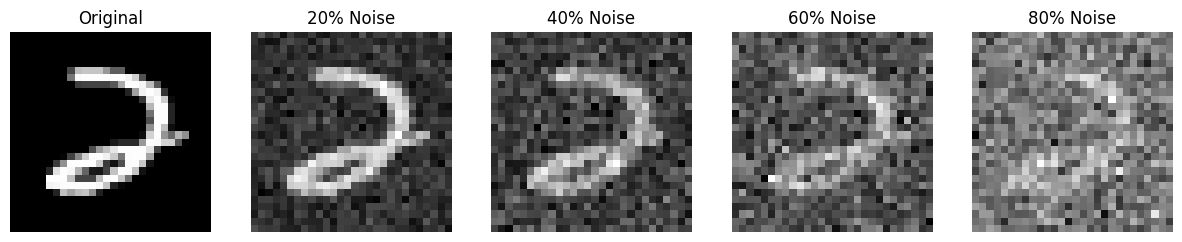

'\n# Try a non-linear noise schedule\nbeta_alt = torch.linspace(beta_start, beta_end, n_steps)**2\nalpha_alt = 1 - beta_alt\nalpha_bar_alt = torch.cumprod(alpha_alt, dim=0)\n# How would this affect the diffusion process?\n'

In [48]:
# Visualization function to show how noise progressively affects images
def show_noise_progression(image, num_steps=5):
    """
    Visualize how an image gets progressively noisier in the diffusion process.

    Args:
        image (torch.Tensor): Original clean image [C, H, W]
        num_steps (int): Number of noise levels to show
    """
    plt.figure(figsize=(15, 3))

    # Show original image
    plt.subplot(1, num_steps, 1)
    if IMG_CH == 1:  # Grayscale image
        plt.imshow(image[0].cpu(), cmap='gray')
    else:  # Color image
        img = image.permute(1, 2, 0).cpu()  # Change from [C,H,W] to [H,W,C]
        if img.min() < 0:  # If normalized between -1 and 1
            img = (img + 1) / 2  # Rescale to [0,1] for display
        plt.imshow(img)
    plt.title('Original')
    plt.axis('off')

    # Show progressively noisier versions
    for i in range(1, num_steps):
        # Calculate timestep index based on percentage through the process
        t_idx = int((i/num_steps) * n_steps)
        t = torch.tensor([t_idx]).to(device)

        # Add noise corresponding to timestep t
        noisy_image, _ = add_noise(image.unsqueeze(0), t)

        # Display the noisy image
        plt.subplot(1, num_steps, i+1)
        if IMG_CH == 1:
            plt.imshow(noisy_image[0][0].cpu(), cmap='gray')
        else:
            img = noisy_image[0].permute(1, 2, 0).cpu()
            if img.min() < 0:
                img = (img + 1) / 2
            plt.imshow(img)
        plt.title(f'{int((i/num_steps) * 100)}% Noise')
        plt.axis('off')
    plt.show()

# Show an example of noise progression on a real image
sample_batch = next(iter(train_dataloader))  # Get first batch
sample_image = sample_batch[0][0].to(device)  # Get first image
show_noise_progression(sample_image)

# Student Activity: Try different noise schedules
# Uncomment and modify these lines to experiment:
"""
# Try a non-linear noise schedule
beta_alt = torch.linspace(beta_start, beta_end, n_steps)**2
alpha_alt = 1 - beta_alt
alpha_bar_alt = torch.cumprod(alpha_alt, dim=0)
# How would this affect the diffusion process?
"""

In [49]:
def count_model_parameters(model):
    """
    Counts the total and trainable parameters of a PyTorch model.
    """
    total_params = sum(p.numel() for p in model.parameters())
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

    print(f"=== Model Parameter Count ===")
    print(f"Total Parameters:     {total_params:,}")
    print(f"Trainable Parameters: {trainable_params:,}")
    return total_params, trainable_params

# Example usage with the UNet model once initialized:
# count_model_parameters(model)

## Step 5: Training Our Model

Now we'll teach our AI to generate images. This process:
1. Takes a clear image
2. Adds random noise to it
3. Asks our AI to predict what noise was added
4. Helps our AI learn from its mistakes

This will take a while, but we'll see progress as it learns!

In [50]:
# Define helper function to validate model parameters locally
def validate_model_parameters(model):
    """
    Counts model parameters and estimates memory usage.
    """
    total_params = sum(p.numel() for p in model.parameters())
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

    print(f"Total parameters: {total_params:,}")
    print(f"Trainable parameters: {trainable_params:,}")

    # Estimate memory requirements
    param_memory = total_params * 4 / (1024 ** 2)  # MB for params (float32)
    grad_memory = trainable_params * 4 / (1024 ** 2)  # MB for gradients
    buffer_memory = param_memory * 2  # Optimizer state, activations, etc.
    print(f"Estimated GPU memory usage: {param_memory + grad_memory + buffer_memory:.1f} MB")

# Re-create our model with corrected UpBlock and move it to the device
model = UNet(
    T=n_steps,
    img_ch=IMG_CH,
    img_size=IMG_SIZE,
    down_chs=(32, 64, 128),
    t_embed_dim=8,
    c_embed_dim=N_CLASSES
).to(device)

# Print model summary
print(f"\n{'='*50}")
print(f"MODEL ARCHITECTURE SUMMARY")
print(f"{'='*50}")
print(f"Input resolution: {IMG_SIZE}x{IMG_SIZE}")
print(f"Input channels: {IMG_CH}")
print(f"Time steps: {n_steps}")
print(f"Condition classes: {N_CLASSES}")
print(f"GPU acceleration: {'Yes' if device.type == 'cuda' else 'No'}")

# Validate model parameters and estimate memory requirements using local definition
validate_model_parameters(model)

# Set up the optimizer with parameters tuned for diffusion models
initial_lr = 0.001
weight_decay = 1e-5

optimizer = Adam(
    model.parameters(),
    lr=initial_lr,
    weight_decay=weight_decay
)

# Learning rate scheduler to reduce LR when validation loss plateaus
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='min',
    factor=0.5,
    patience=5,
    min_lr=1e-6
)

Created DownBlock: in_chs=32, out_chs=64, spatial_reduction=2x
Created DownBlock: in_chs=64, out_chs=128, spatial_reduction=2x
Created UpBlock: in_chs=128, out_chs=64, spatial_increase=2x
Created UpBlock: in_chs=64, out_chs=32, spatial_increase=2x
Created UNet with 3 scale levels
Channel dimensions: (32, 64, 128)

MODEL ARCHITECTURE SUMMARY
Input resolution: 28x28
Input channels: 1
Time steps: 100
Condition classes: 10
GPU acceleration: Yes
Total parameters: 1,581,409
Trainable parameters: 1,581,409
Estimated GPU memory usage: 24.1 MB


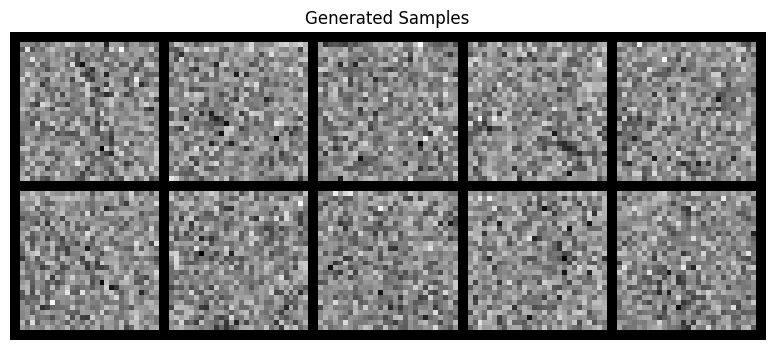

In [51]:
# Generate and display a preview of digits from the model
def generate_samples(model, n_samples=10):
    model.eval()
    with torch.no_grad():
        samples = []
        for digit in range(min(n_samples, 10)):
            x = torch.randn(1, IMG_CH, IMG_SIZE, IMG_SIZE).to(device)
            c = torch.tensor([digit]).to(device)
            c_one_hot = F.one_hot(c, N_CLASSES).float().to(device)
            c_mask = torch.ones_like(c.unsqueeze(-1)).to(device)

            for t in range(n_steps-1, -1, -1):
                t_batch = torch.full((1,), t).to(device)
                x = remove_noise(x, t_batch, model, c_one_hot, c_mask)
            samples.append(x)

        samples = torch.cat(samples, dim=0)
        grid = make_grid(samples, nrow=min(n_samples, 5), normalize=True)

        plt.figure(figsize=(10, 4))
        if IMG_CH == 1:
            plt.imshow(grid[0].cpu(), cmap='gray')
        else:
            plt.imshow(grid.permute(1, 2, 0).cpu())
        plt.axis('off')
        plt.title('Generated Samples')
        plt.show()

generate_samples(model, n_samples=10)

In [52]:
# Define helper functions needed for training and evaluation
def validate_model_parameters(model):
    """
    Counts model parameters and estimates memory usage.
    """
    total_params = sum(p.numel() for p in model.parameters())
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

    print(f"Total parameters: {total_params:,}")
    print(f"Trainable parameters: {trainable_params:,}")

    # Estimate memory requirements (very approximate)
    param_memory = total_params * 4 / (1024 ** 2)  # MB for params (float32)
    grad_memory = trainable_params * 4 / (1024 ** 2)  # MB for gradients
    buffer_memory = param_memory * 2  # Optimizer state, forward activations, etc.

    print(f"Estimated GPU memory usage: {param_memory + grad_memory + buffer_memory:.1f} MB")

# Define helper functions for verifying data ranges
def verify_data_range(dataloader, name="Dataset"):
    """
    Verifies the range and integrity of the data.
    """
    batch = next(iter(dataloader))[0]
    print(f"\n{name} range check:")
    print(f"Shape: {batch.shape}")
    print(f"Data type: {batch.dtype}")
    print(f"Min value: {batch.min().item():.2f}")
    print(f"Max value: {batch.max().item():.2f}")
    print(f"Contains NaN: {torch.isnan(batch).any().item()}")
    print(f"Contains Inf: {torch.isinf(batch).any().item()}")

# Define helper functions for generating samples during training
def generate_samples(model, n_samples=10):
    """
    Generates sample images using the model for visualization during training.
    """
    model.eval()
    with torch.no_grad():
        # Generate digits 0-9 for visualization
        samples = []
        for digit in range(min(n_samples, 10)):
            # Start with random noise
            x = torch.randn(1, IMG_CH, IMG_SIZE, IMG_SIZE).to(device)

            # Set up conditioning for the digit
            c = torch.tensor([digit]).to(device)
            c_one_hot = F.one_hot(c, N_CLASSES).float().to(device)
            c_mask = torch.ones_like(c.unsqueeze(-1)).to(device)

            # Remove noise step by step
            for t in range(n_steps-1, -1, -1):
                t_batch = torch.full((1,), t).to(device)
                x = remove_noise(x, t_batch, model, c_one_hot, c_mask)

            samples.append(x)

        # Combine samples and display
        samples = torch.cat(samples, dim=0)
        grid = make_grid(samples, nrow=min(n_samples, 5), normalize=True)

        plt.figure(figsize=(10, 4))

        # Display based on channel configuration
        if IMG_CH == 1:
            plt.imshow(grid[0].cpu(), cmap='gray')
        else:
            plt.imshow(grid.permute(1, 2, 0).cpu())

        plt.axis('off')
        plt.title('Generated Samples')
        plt.show()

# Define helper functions for safely saving models
def safe_save_model(model, path, optimizer=None, epoch=None, best_loss=None):
    """
    Safely saves model with error handling and backup.
    """
    try:
        # Create a dictionary with all the elements to save
        save_dict = {
            'model_state_dict': model.state_dict(),
        }

        # Add optional elements if provided
        if optimizer is not None:
            save_dict['optimizer_state_dict'] = optimizer.state_dict()
        if epoch is not None:
            save_dict['epoch'] = epoch
        if best_loss is not None:
            save_dict['best_loss'] = best_loss

        # Create a backup of previous checkpoint if it exists
        if os.path.exists(path):
            backup_path = path + '.backup'
            try:
                os.replace(path, backup_path)
                print(f"Created backup at {backup_path}")
            except Exception as e:
                print(f"Warning: Could not create backup - {e}")

        # Save the new checkpoint
        torch.save(save_dict, path)
        print(f"Model successfully saved to {path}")

    except Exception as e:
        print(f"Error saving model: {e}")
        print("Attempting emergency save...")

        try:
            emergency_path = path + '.emergency'
            torch.save(model.state_dict(), emergency_path)
            print(f"Emergency save successful: {emergency_path}")
        except:
            print("Emergency save failed. Could not save model.")

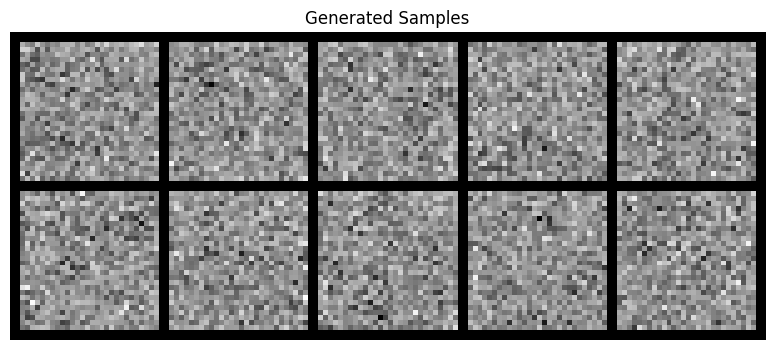

In [53]:
# Define generate_samples locally to prevent NameError
def generate_samples(model, n_samples=10):
    model.eval()
    with torch.no_grad():
        samples = []
        for digit in range(min(n_samples, 10)):
            x = torch.randn(1, IMG_CH, IMG_SIZE, IMG_SIZE).to(device)
            c = torch.tensor([digit]).to(device)
            c_one_hot = F.one_hot(c, N_CLASSES).float().to(device)
            c_mask = torch.ones_like(c.unsqueeze(-1)).to(device)

            for t in range(n_steps-1, -1, -1):
                t_batch = torch.full((1,), t).to(device)
                x = remove_noise(x, t_batch, model, c_one_hot, c_mask)
            samples.append(x)

        samples = torch.cat(samples, dim=0)
        grid = make_grid(samples, nrow=min(n_samples, 5), normalize=True)

        plt.figure(figsize=(10, 4))
        if IMG_CH == 1:
            plt.imshow(grid[0].cpu(), cmap='gray')
        else:
            plt.imshow(grid.permute(1, 2, 0).cpu())
        plt.axis('off')
        plt.title('Generated Samples')
        plt.show()

# Run the generation process
generate_samples(model, n_samples=10)

In [54]:
# Define helper function for verifying data ranges locally to ensure it is defined
def verify_data_range(dataloader, name="Dataset"):
    """
    Verifies the range and integrity of the data.
    """
    batch = next(iter(dataloader))[0]
    print(f"\n{name} range check:")
    print(f"Shape: {batch.shape}")
    print(f"Data type: {batch.dtype}")
    print(f"Min value: {batch.min().item():.2f}")
    print(f"Max value: {batch.max().item():.2f}")
    print(f"Contains NaN: {torch.isnan(batch).any().item()}")
    print(f"Contains Inf: {torch.isinf(batch).any().item()}")

# Verify the range and integrity of our training dataloader batches
verify_data_range(train_dataloader, name="Training Dataset")


Training Dataset range check:
Shape: torch.Size([64, 1, 28, 28])
Data type: torch.float32
Min value: -1.00
Max value: 1.00
Contains NaN: False
Contains Inf: False


In [55]:
# Implementation of the training step function
def train_step(x, c):
    """
    Performs a single training step for the diffusion model.

    This function:
    1. Prepares class conditioning
    2. Samples random timesteps for each image
    3. Adds corresponding noise to the images
    4. Asks the model to predict the noise
    5. Calculates the loss between predicted and actual noise

    Args:
        x (torch.Tensor): Batch of clean images [batch_size, channels, height, width]
        c (torch.Tensor): Batch of class labels [batch_size]

    Returns:
        torch.Tensor: Mean squared error loss value
    """
    # Convert number labels to one-hot encoding for class conditioning
    c_one_hot = F.one_hot(c, N_CLASSES).float().to(device)

    # Create conditioning mask (all ones for standard training)
    c_mask = torch.ones_like(c.unsqueeze(-1)).to(device)

    # Pick random timesteps for each image in the batch
    t = torch.randint(0, n_steps, (x.shape[0],)).to(device)

    # Add noise to images according to the forward diffusion process
    x_t, noise = add_noise(x, t)

    # The model tries to predict the exact noise that was added
    predicted_noise = model(x_t, t, c_one_hot, c_mask)

    # Calculate loss comparing predicted and actual noise using MSE
    loss = F.mse_loss(predicted_noise, noise)

    return loss


STARTING TRAINING

Epoch 1/30
--------------------
  Step 0/750, Loss: 1.1960
  Step 100/750, Loss: 0.1119
  Step 200/750, Loss: 0.0858
  Step 300/750, Loss: 0.0848
  Step 400/750, Loss: 0.0859
  Step 500/750, Loss: 0.0717
  Generating samples...


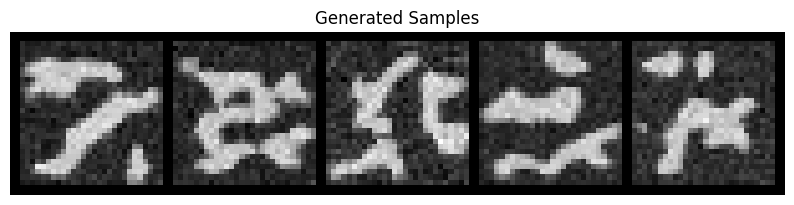

  Step 600/750, Loss: 0.0867
  Step 700/750, Loss: 0.0738

Training - Epoch 1 average loss: 0.1000
Running validation...
Validation - Epoch 1 average loss: 0.0709
Learning rate: 0.001000

Generating samples for visual progress check...


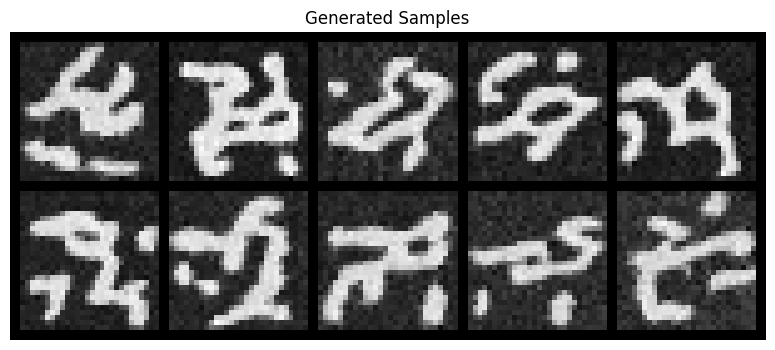

Created backup at best_diffusion_model.pt.backup
Model successfully saved to best_diffusion_model.pt
✓ New best model saved! (Val Loss: 0.0709)


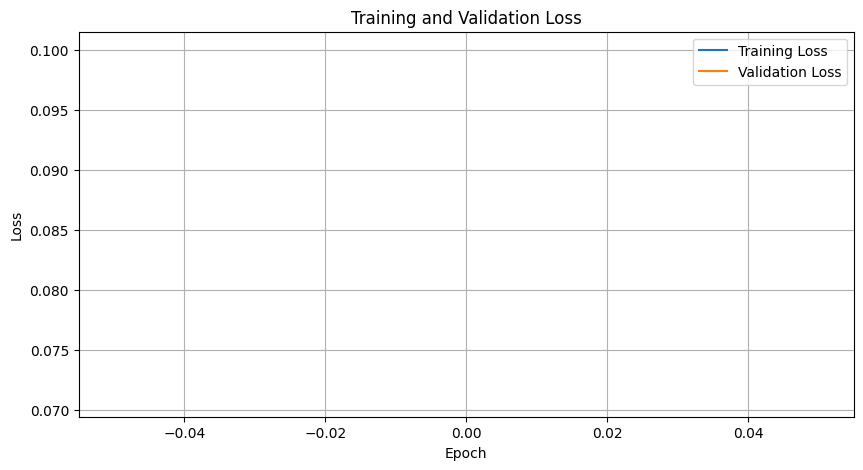


Epoch 2/30
--------------------
  Step 0/750, Loss: 0.0772
  Step 100/750, Loss: 0.0698
  Step 200/750, Loss: 0.0763
  Step 300/750, Loss: 0.0659
  Step 400/750, Loss: 0.0729
  Step 500/750, Loss: 0.0730
  Generating samples...


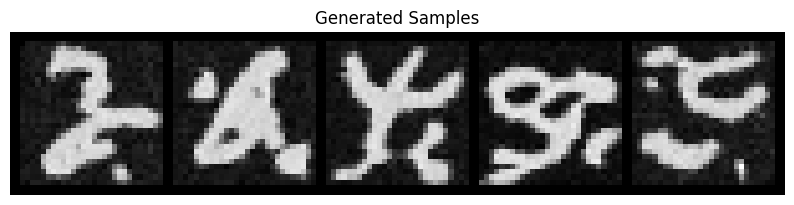

  Step 600/750, Loss: 0.0829
  Step 700/750, Loss: 0.0692

Training - Epoch 2 average loss: 0.0690
Running validation...
Validation - Epoch 2 average loss: 0.0661
Learning rate: 0.001000
Created backup at best_diffusion_model.pt.backup
Model successfully saved to best_diffusion_model.pt
✓ New best model saved! (Val Loss: 0.0661)

Epoch 3/30
--------------------
  Step 0/750, Loss: 0.0751
  Step 100/750, Loss: 0.0722
  Step 200/750, Loss: 0.0654
  Step 300/750, Loss: 0.0663
  Step 400/750, Loss: 0.0670
  Step 500/750, Loss: 0.0623
  Generating samples...


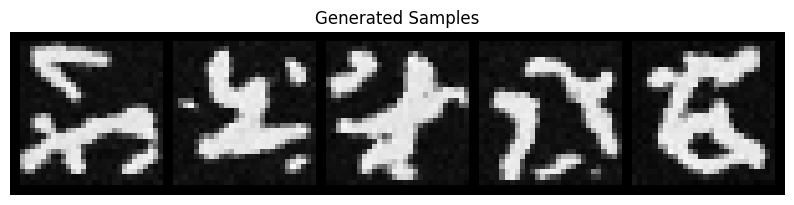

  Step 600/750, Loss: 0.0704
  Step 700/750, Loss: 0.0660

Training - Epoch 3 average loss: 0.0651
Running validation...
Validation - Epoch 3 average loss: 0.0635
Learning rate: 0.001000

Generating samples for visual progress check...


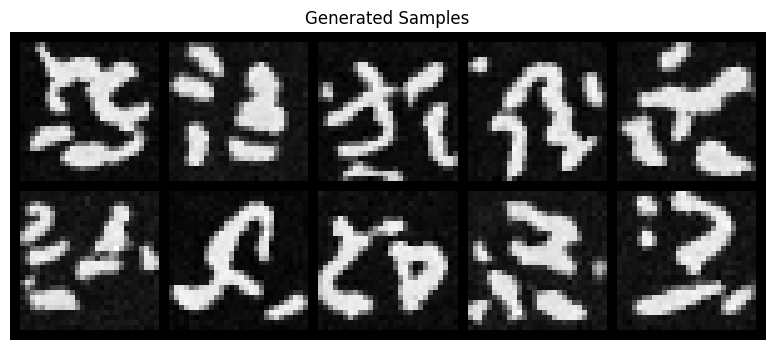

Created backup at best_diffusion_model.pt.backup
Model successfully saved to best_diffusion_model.pt
✓ New best model saved! (Val Loss: 0.0635)

Epoch 4/30
--------------------
  Step 0/750, Loss: 0.0697
  Step 100/750, Loss: 0.0634
  Step 200/750, Loss: 0.0623
  Step 300/750, Loss: 0.0609
  Step 400/750, Loss: 0.0574
  Step 500/750, Loss: 0.0585
  Generating samples...


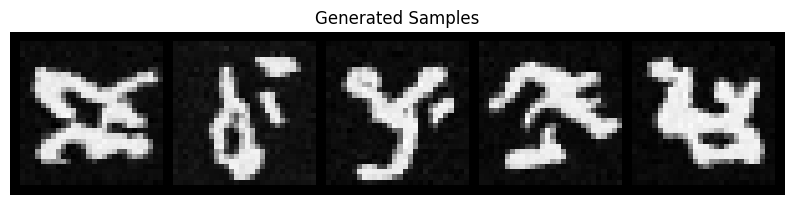

  Step 600/750, Loss: 0.0633
  Step 700/750, Loss: 0.0595

Training - Epoch 4 average loss: 0.0634
Running validation...
Validation - Epoch 4 average loss: 0.0631
Learning rate: 0.001000
Created backup at best_diffusion_model.pt.backup
Model successfully saved to best_diffusion_model.pt
✓ New best model saved! (Val Loss: 0.0631)

Epoch 5/30
--------------------
  Step 0/750, Loss: 0.0566
  Step 100/750, Loss: 0.0559
  Step 200/750, Loss: 0.0679
  Step 300/750, Loss: 0.0681
  Step 400/750, Loss: 0.0515
  Step 500/750, Loss: 0.0551
  Generating samples...


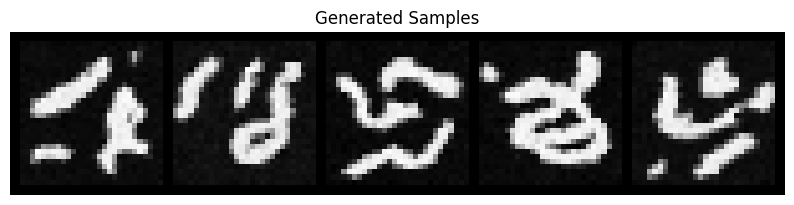

  Step 600/750, Loss: 0.0579
  Step 700/750, Loss: 0.0493

Training - Epoch 5 average loss: 0.0622
Running validation...
Validation - Epoch 5 average loss: 0.0608
Learning rate: 0.001000

Generating samples for visual progress check...


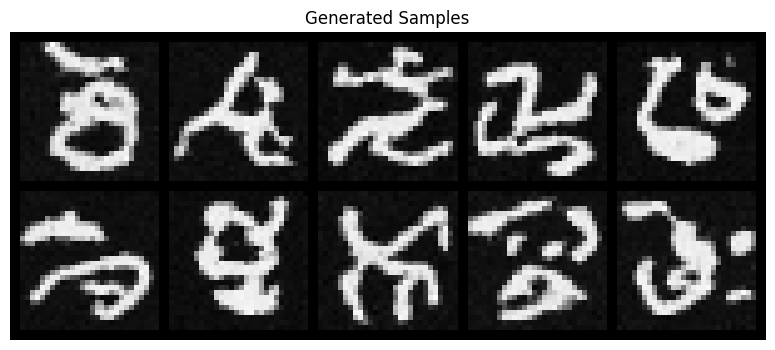

Created backup at best_diffusion_model.pt.backup
Model successfully saved to best_diffusion_model.pt
✓ New best model saved! (Val Loss: 0.0608)

Epoch 6/30
--------------------
  Step 0/750, Loss: 0.0661
  Step 100/750, Loss: 0.0645
  Step 200/750, Loss: 0.0529
  Step 300/750, Loss: 0.0459
  Step 400/750, Loss: 0.0620
  Step 500/750, Loss: 0.0553
  Generating samples...


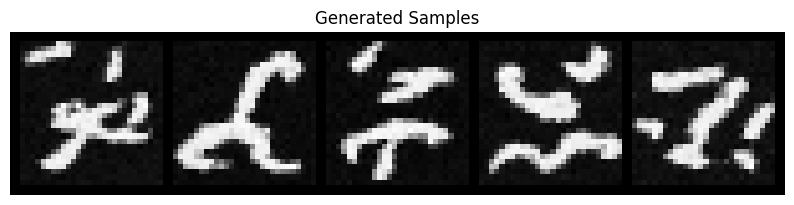

  Step 600/750, Loss: 0.0672
  Step 700/750, Loss: 0.0626

Training - Epoch 6 average loss: 0.0608
Running validation...
Validation - Epoch 6 average loss: 0.0607
Learning rate: 0.001000
Created backup at best_diffusion_model.pt.backup
Model successfully saved to best_diffusion_model.pt
✓ New best model saved! (Val Loss: 0.0607)


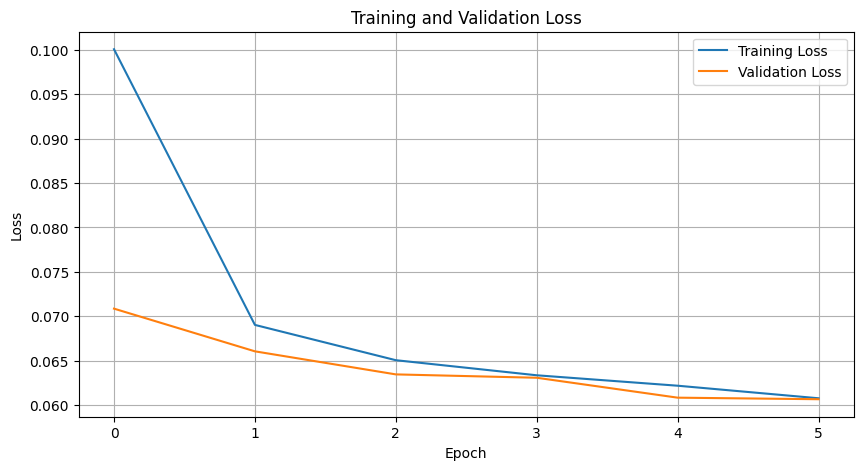


Epoch 7/30
--------------------
  Step 0/750, Loss: 0.0566
  Step 100/750, Loss: 0.0544
  Step 200/750, Loss: 0.0496
  Step 300/750, Loss: 0.0648
  Step 400/750, Loss: 0.0744
  Step 500/750, Loss: 0.0646
  Generating samples...


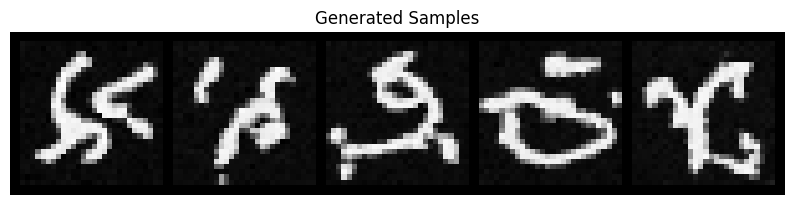

  Step 600/750, Loss: 0.0560
  Step 700/750, Loss: 0.0672

Training - Epoch 7 average loss: 0.0601
Running validation...
Validation - Epoch 7 average loss: 0.0597
Learning rate: 0.001000

Generating samples for visual progress check...


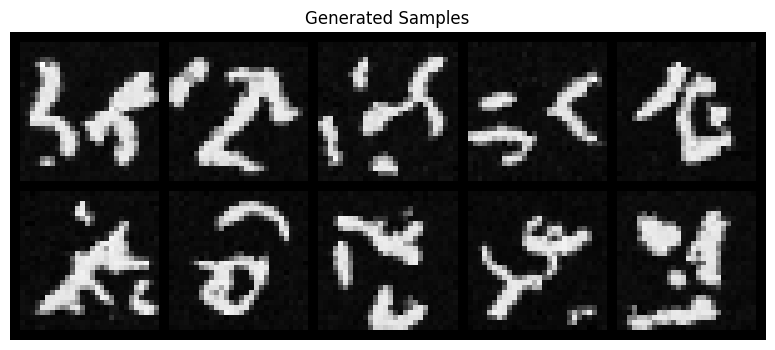

Created backup at best_diffusion_model.pt.backup
Model successfully saved to best_diffusion_model.pt
✓ New best model saved! (Val Loss: 0.0597)

Epoch 8/30
--------------------
  Step 0/750, Loss: 0.0633
  Step 100/750, Loss: 0.0672
  Step 200/750, Loss: 0.0622
  Step 300/750, Loss: 0.0591
  Step 400/750, Loss: 0.0558
  Step 500/750, Loss: 0.0585
  Generating samples...


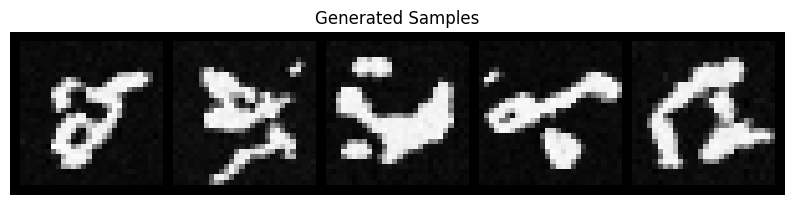

  Step 600/750, Loss: 0.0634
  Step 700/750, Loss: 0.0580

Training - Epoch 8 average loss: 0.0599
Running validation...
Validation - Epoch 8 average loss: 0.0585
Learning rate: 0.001000
Created backup at best_diffusion_model.pt.backup
Model successfully saved to best_diffusion_model.pt
✓ New best model saved! (Val Loss: 0.0585)

Epoch 9/30
--------------------
  Step 0/750, Loss: 0.0601
  Step 100/750, Loss: 0.0493
  Step 200/750, Loss: 0.0558
  Step 300/750, Loss: 0.0580
  Step 400/750, Loss: 0.0542
  Step 500/750, Loss: 0.0572
  Generating samples...


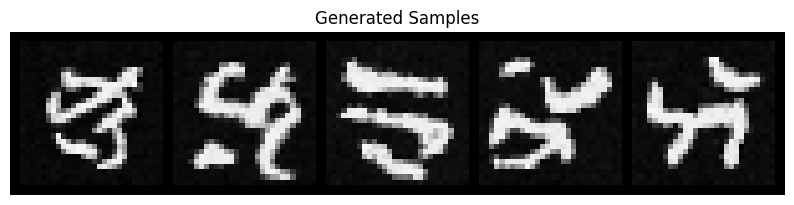

  Step 600/750, Loss: 0.0507
  Step 700/750, Loss: 0.0551

Training - Epoch 9 average loss: 0.0594
Running validation...
Validation - Epoch 9 average loss: 0.0579
Learning rate: 0.001000

Generating samples for visual progress check...


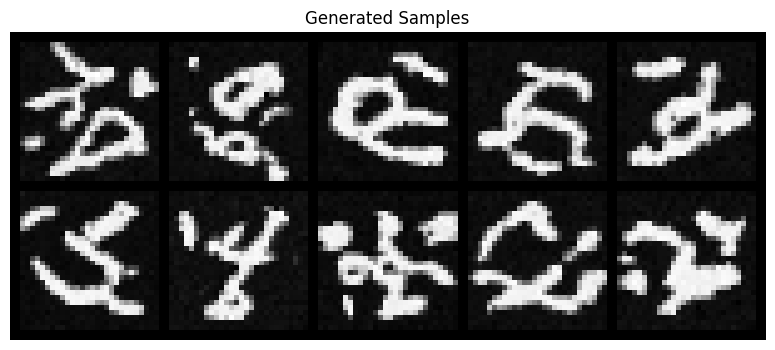

Created backup at best_diffusion_model.pt.backup
Model successfully saved to best_diffusion_model.pt
✓ New best model saved! (Val Loss: 0.0579)

Epoch 10/30
--------------------
  Step 0/750, Loss: 0.0589
  Step 100/750, Loss: 0.0605
  Step 200/750, Loss: 0.0645
  Step 300/750, Loss: 0.0570
  Step 400/750, Loss: 0.0582
  Step 500/750, Loss: 0.0605
  Generating samples...


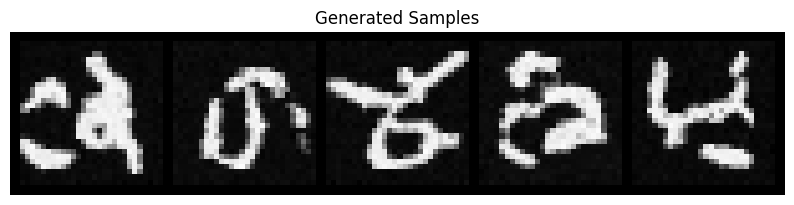

  Step 600/750, Loss: 0.0576
  Step 700/750, Loss: 0.0571

Training - Epoch 10 average loss: 0.0587
Running validation...
Validation - Epoch 10 average loss: 0.0580
Learning rate: 0.001000
No improvement for 1/10 epochs

Epoch 11/30
--------------------
  Step 0/750, Loss: 0.0556
  Step 100/750, Loss: 0.0637
  Step 200/750, Loss: 0.0689
  Step 300/750, Loss: 0.0643
  Step 400/750, Loss: 0.0610
  Step 500/750, Loss: 0.0658
  Generating samples...


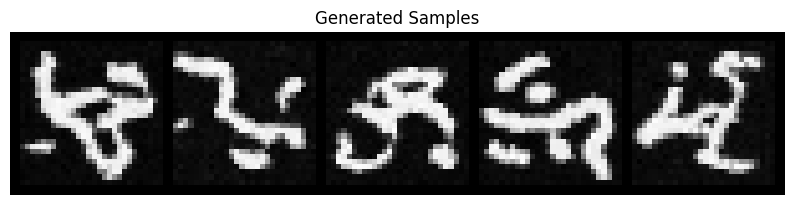

  Step 600/750, Loss: 0.0490
  Step 700/750, Loss: 0.0598

Training - Epoch 11 average loss: 0.0584
Running validation...
Validation - Epoch 11 average loss: 0.0585
Learning rate: 0.001000

Generating samples for visual progress check...


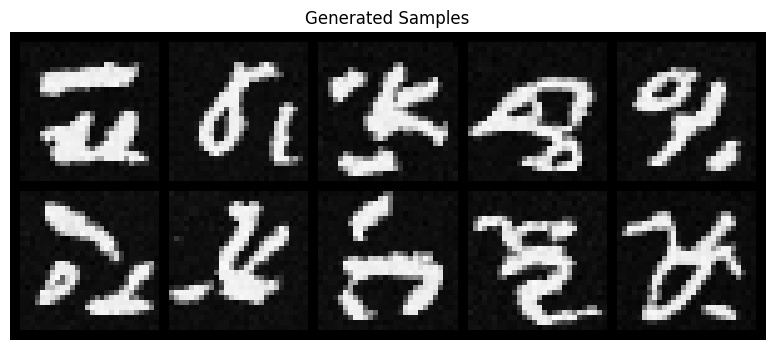

No improvement for 2/10 epochs


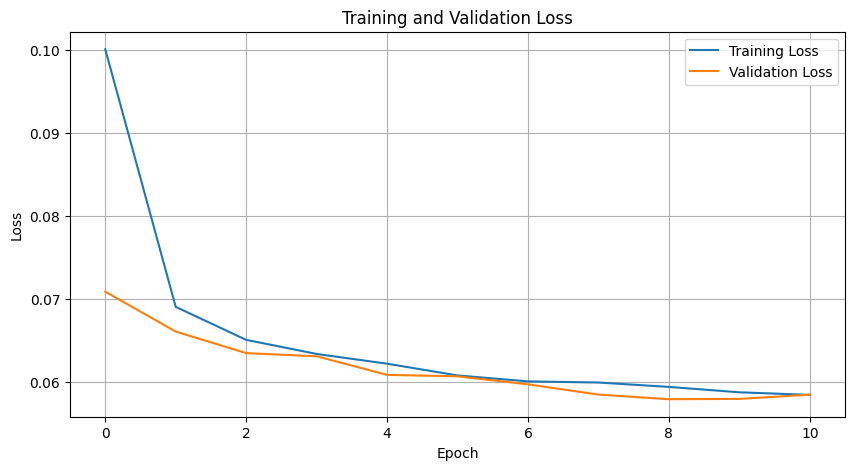


Epoch 12/30
--------------------
  Step 0/750, Loss: 0.0602
  Step 100/750, Loss: 0.0732
  Step 200/750, Loss: 0.0540
  Step 300/750, Loss: 0.0539
  Step 400/750, Loss: 0.0649
  Step 500/750, Loss: 0.0585
  Generating samples...


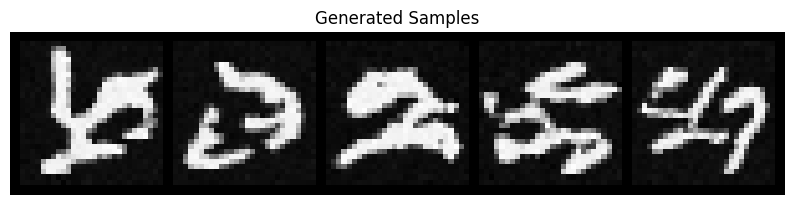

  Step 600/750, Loss: 0.0546
  Step 700/750, Loss: 0.0632

Training - Epoch 12 average loss: 0.0581
Running validation...
Validation - Epoch 12 average loss: 0.0591
Learning rate: 0.001000
No improvement for 3/10 epochs

Epoch 13/30
--------------------
  Step 0/750, Loss: 0.0532
  Step 100/750, Loss: 0.0612
  Step 200/750, Loss: 0.0587
  Step 300/750, Loss: 0.0565
  Step 400/750, Loss: 0.0660
  Step 500/750, Loss: 0.0597
  Generating samples...


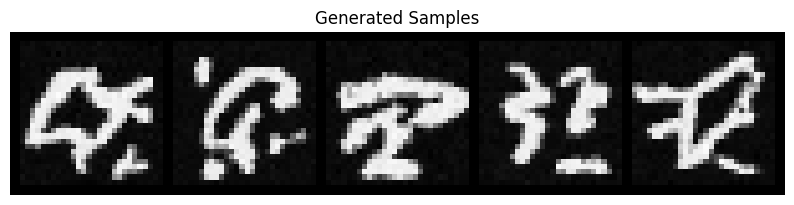

  Step 600/750, Loss: 0.0517
  Step 700/750, Loss: 0.0535

Training - Epoch 13 average loss: 0.0581
Running validation...
Validation - Epoch 13 average loss: 0.0579
Learning rate: 0.001000

Generating samples for visual progress check...


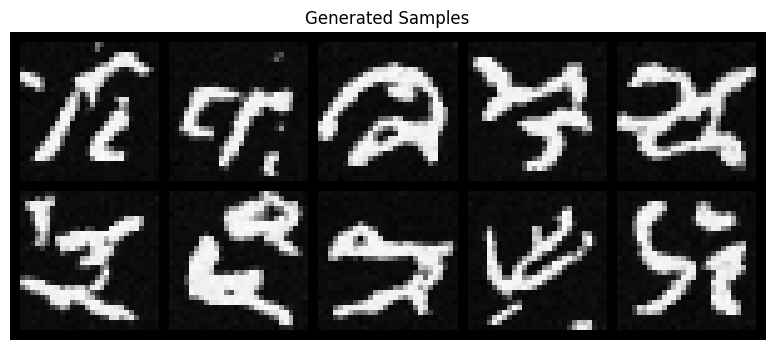

Created backup at best_diffusion_model.pt.backup
Model successfully saved to best_diffusion_model.pt
✓ New best model saved! (Val Loss: 0.0579)

Epoch 14/30
--------------------
  Step 0/750, Loss: 0.0552
  Step 100/750, Loss: 0.0542
  Step 200/750, Loss: 0.0584
  Step 300/750, Loss: 0.0646
  Step 400/750, Loss: 0.0580
  Step 500/750, Loss: 0.0582
  Generating samples...


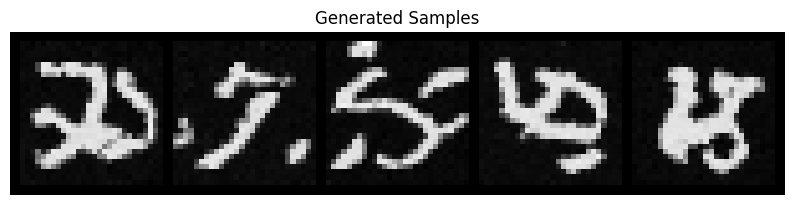

  Step 600/750, Loss: 0.0542
  Step 700/750, Loss: 0.0583

Training - Epoch 14 average loss: 0.0579
Running validation...
Validation - Epoch 14 average loss: 0.0576
Learning rate: 0.001000
Created backup at best_diffusion_model.pt.backup
Model successfully saved to best_diffusion_model.pt
✓ New best model saved! (Val Loss: 0.0576)

Epoch 15/30
--------------------
  Step 0/750, Loss: 0.0552
  Step 100/750, Loss: 0.0577
  Step 200/750, Loss: 0.0651
  Step 300/750, Loss: 0.0559
  Step 400/750, Loss: 0.0620
  Step 500/750, Loss: 0.0610
  Generating samples...


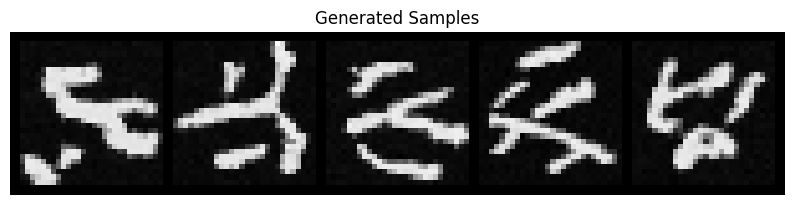

  Step 600/750, Loss: 0.0576
  Step 700/750, Loss: 0.0571

Training - Epoch 15 average loss: 0.0578
Running validation...
Validation - Epoch 15 average loss: 0.0580
Learning rate: 0.001000

Generating samples for visual progress check...


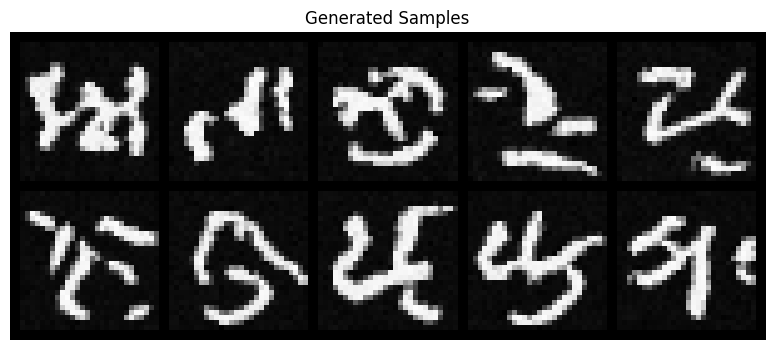

No improvement for 1/10 epochs

Epoch 16/30
--------------------
  Step 0/750, Loss: 0.0534
  Step 100/750, Loss: 0.0552
  Step 200/750, Loss: 0.0652
  Step 300/750, Loss: 0.0547
  Step 400/750, Loss: 0.0603
  Step 500/750, Loss: 0.0543
  Generating samples...


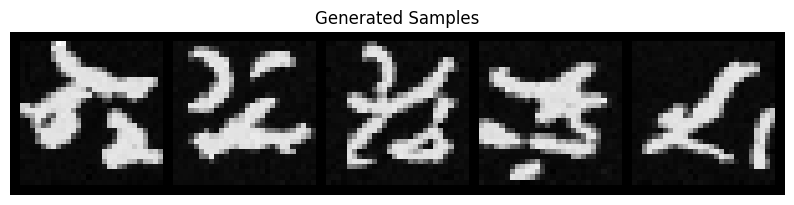

  Step 600/750, Loss: 0.0592
  Step 700/750, Loss: 0.0504

Training - Epoch 16 average loss: 0.0576
Running validation...
Validation - Epoch 16 average loss: 0.0574
Learning rate: 0.001000
Created backup at best_diffusion_model.pt.backup
Model successfully saved to best_diffusion_model.pt
✓ New best model saved! (Val Loss: 0.0574)


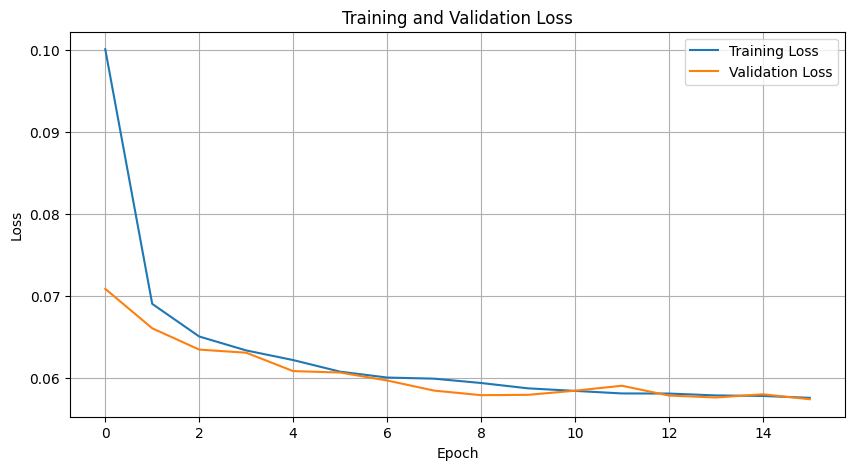


Epoch 17/30
--------------------
  Step 0/750, Loss: 0.0534
  Step 100/750, Loss: 0.0554
  Step 200/750, Loss: 0.0582
  Step 300/750, Loss: 0.0624
  Step 400/750, Loss: 0.0602
  Step 500/750, Loss: 0.0580
  Generating samples...


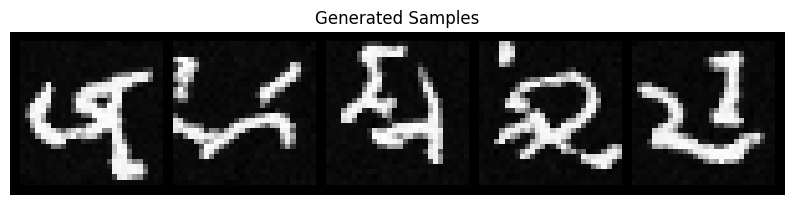

  Step 600/750, Loss: 0.0626
  Step 700/750, Loss: 0.0510

Training - Epoch 17 average loss: 0.0573
Running validation...
Validation - Epoch 17 average loss: 0.0564
Learning rate: 0.001000

Generating samples for visual progress check...


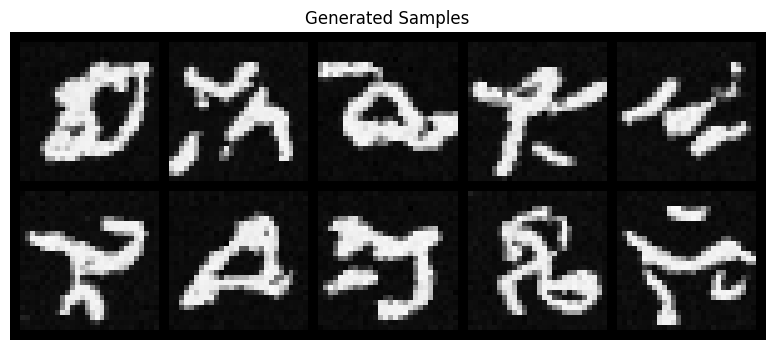

Created backup at best_diffusion_model.pt.backup
Model successfully saved to best_diffusion_model.pt
✓ New best model saved! (Val Loss: 0.0564)

Epoch 18/30
--------------------
  Step 0/750, Loss: 0.0542
  Step 100/750, Loss: 0.0592
  Step 200/750, Loss: 0.0493
  Step 300/750, Loss: 0.0544
  Step 400/750, Loss: 0.0522
  Step 500/750, Loss: 0.0585
  Generating samples...


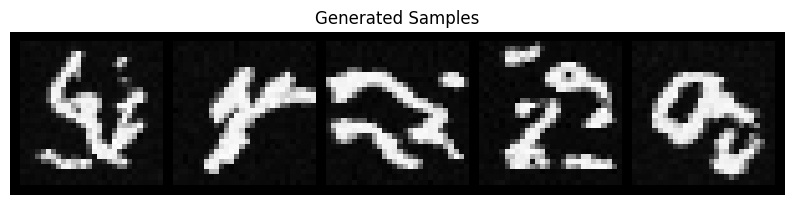

  Step 600/750, Loss: 0.0587
  Step 700/750, Loss: 0.0672

Training - Epoch 18 average loss: 0.0569
Running validation...
Validation - Epoch 18 average loss: 0.0580
Learning rate: 0.001000
No improvement for 1/10 epochs

Epoch 19/30
--------------------
  Step 0/750, Loss: 0.0599
  Step 100/750, Loss: 0.0589
  Step 200/750, Loss: 0.0563
  Step 300/750, Loss: 0.0586
  Step 400/750, Loss: 0.0627
  Step 500/750, Loss: 0.0567
  Generating samples...


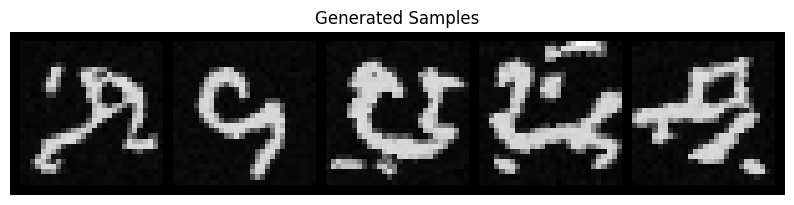

  Step 600/750, Loss: 0.0522
  Step 700/750, Loss: 0.0541

Training - Epoch 19 average loss: 0.0569
Running validation...
Validation - Epoch 19 average loss: 0.0585
Learning rate: 0.001000

Generating samples for visual progress check...


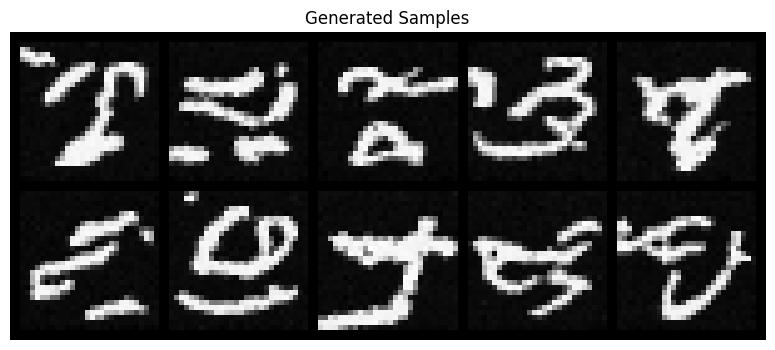

No improvement for 2/10 epochs

Epoch 20/30
--------------------
  Step 0/750, Loss: 0.0623
  Step 100/750, Loss: 0.0548
  Step 200/750, Loss: 0.0534
  Step 300/750, Loss: 0.0595
  Step 400/750, Loss: 0.0495
  Step 500/750, Loss: 0.0606
  Generating samples...


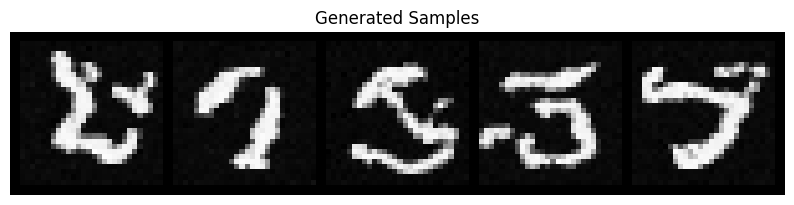

  Step 600/750, Loss: 0.0560
  Step 700/750, Loss: 0.0519

Training - Epoch 20 average loss: 0.0568
Running validation...
Validation - Epoch 20 average loss: 0.0576
Learning rate: 0.001000
No improvement for 3/10 epochs

Epoch 21/30
--------------------
  Step 0/750, Loss: 0.0538
  Step 100/750, Loss: 0.0541
  Step 200/750, Loss: 0.0643
  Step 300/750, Loss: 0.0613
  Step 400/750, Loss: 0.0675
  Step 500/750, Loss: 0.0581
  Generating samples...


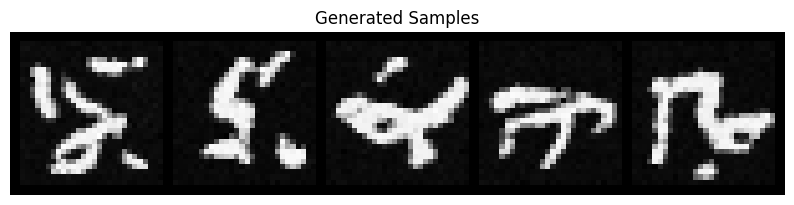

  Step 600/750, Loss: 0.0595
  Step 700/750, Loss: 0.0643

Training - Epoch 21 average loss: 0.0567
Running validation...
Validation - Epoch 21 average loss: 0.0566
Learning rate: 0.001000

Generating samples for visual progress check...


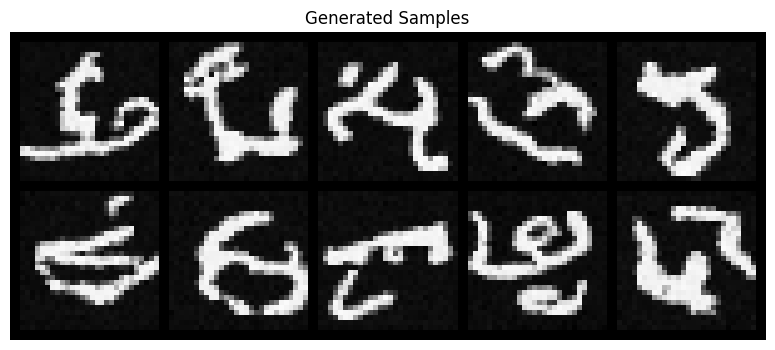

No improvement for 4/10 epochs


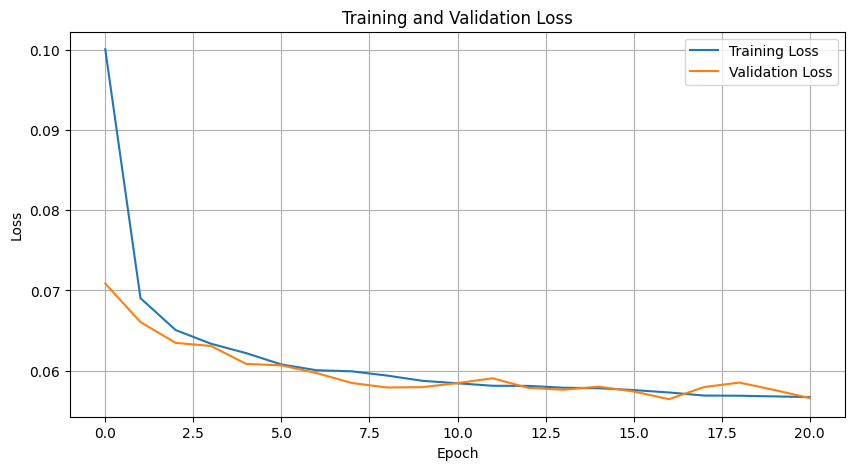


Epoch 22/30
--------------------
  Step 0/750, Loss: 0.0571
  Step 100/750, Loss: 0.0538
  Step 200/750, Loss: 0.0551
  Step 300/750, Loss: 0.0550
  Step 400/750, Loss: 0.0561
  Step 500/750, Loss: 0.0577
  Generating samples...


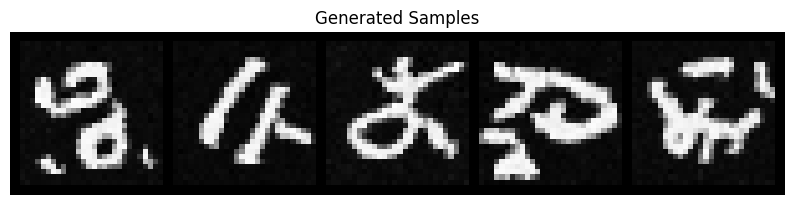

  Step 600/750, Loss: 0.0574
  Step 700/750, Loss: 0.0612

Training - Epoch 22 average loss: 0.0571
Running validation...
Validation - Epoch 22 average loss: 0.0569
Learning rate: 0.001000
No improvement for 5/10 epochs

Epoch 23/30
--------------------
  Step 0/750, Loss: 0.0585
  Step 100/750, Loss: 0.0512
  Step 200/750, Loss: 0.0538
  Step 300/750, Loss: 0.0473
  Step 400/750, Loss: 0.0534
  Step 500/750, Loss: 0.0555
  Generating samples...


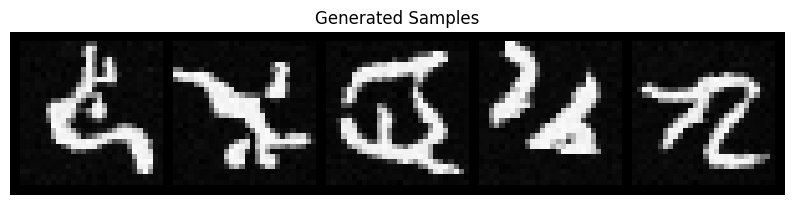

  Step 600/750, Loss: 0.0569
  Step 700/750, Loss: 0.0634

Training - Epoch 23 average loss: 0.0562
Running validation...
Validation - Epoch 23 average loss: 0.0562
Learning rate: 0.001000

Generating samples for visual progress check...


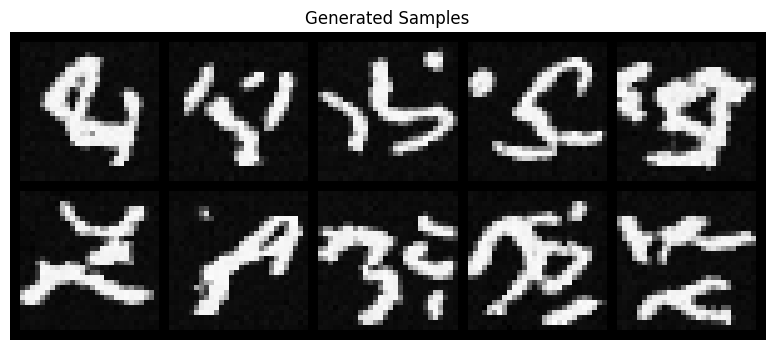

Created backup at best_diffusion_model.pt.backup
Model successfully saved to best_diffusion_model.pt
✓ New best model saved! (Val Loss: 0.0562)

Epoch 24/30
--------------------
  Step 0/750, Loss: 0.0552
  Step 100/750, Loss: 0.0494
  Step 200/750, Loss: 0.0552
  Step 300/750, Loss: 0.0565
  Step 400/750, Loss: 0.0531
  Step 500/750, Loss: 0.0591
  Generating samples...


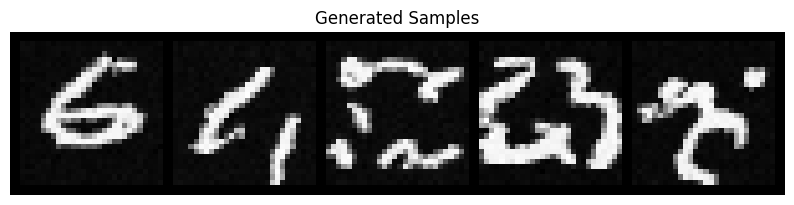

  Step 600/750, Loss: 0.0578
  Step 700/750, Loss: 0.0548

Training - Epoch 24 average loss: 0.0567
Running validation...
Validation - Epoch 24 average loss: 0.0569
Learning rate: 0.001000
No improvement for 1/10 epochs

Epoch 25/30
--------------------
  Step 0/750, Loss: 0.0622
  Step 100/750, Loss: 0.0638
  Step 200/750, Loss: 0.0554
  Step 300/750, Loss: 0.0598
  Step 400/750, Loss: 0.0545
  Step 500/750, Loss: 0.0681
  Generating samples...


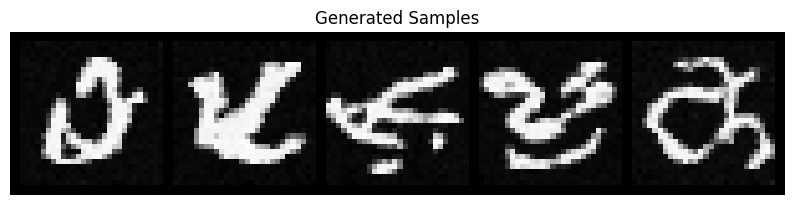

  Step 600/750, Loss: 0.0498
  Step 700/750, Loss: 0.0620

Training - Epoch 25 average loss: 0.0566
Running validation...
Validation - Epoch 25 average loss: 0.0568
Learning rate: 0.001000

Generating samples for visual progress check...


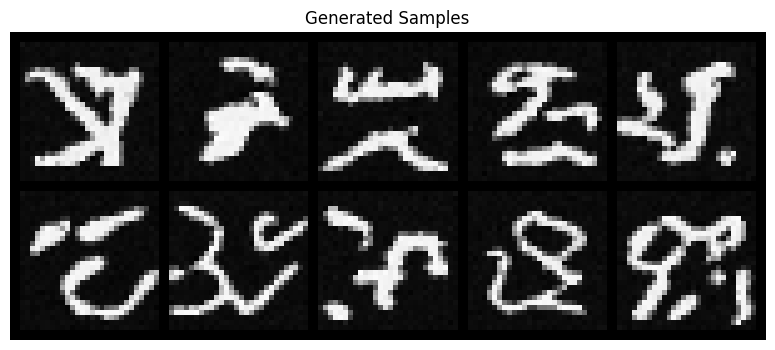

No improvement for 2/10 epochs

Epoch 26/30
--------------------
  Step 0/750, Loss: 0.0719
  Step 100/750, Loss: 0.0625
  Step 200/750, Loss: 0.0494
  Step 300/750, Loss: 0.0576
  Step 400/750, Loss: 0.0628
  Step 500/750, Loss: 0.0570
  Generating samples...


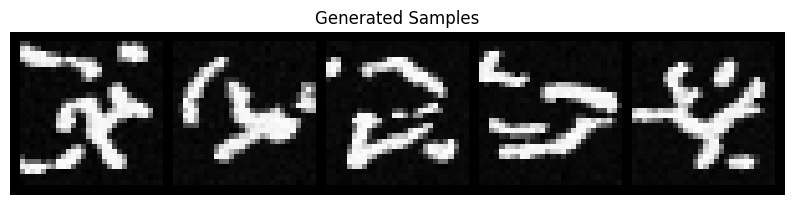

  Step 600/750, Loss: 0.0626
  Step 700/750, Loss: 0.0578

Training - Epoch 26 average loss: 0.0562
Running validation...
Validation - Epoch 26 average loss: 0.0562
Learning rate: 0.001000
Created backup at best_diffusion_model.pt.backup
Model successfully saved to best_diffusion_model.pt
✓ New best model saved! (Val Loss: 0.0562)


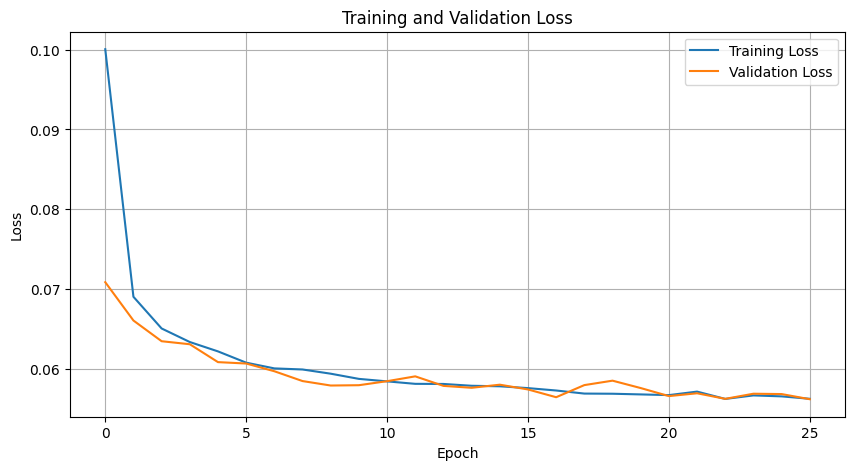


Epoch 27/30
--------------------
  Step 0/750, Loss: 0.0490
  Step 100/750, Loss: 0.0531
  Step 200/750, Loss: 0.0562
  Step 300/750, Loss: 0.0665
  Step 400/750, Loss: 0.0486
  Step 500/750, Loss: 0.0559
  Generating samples...


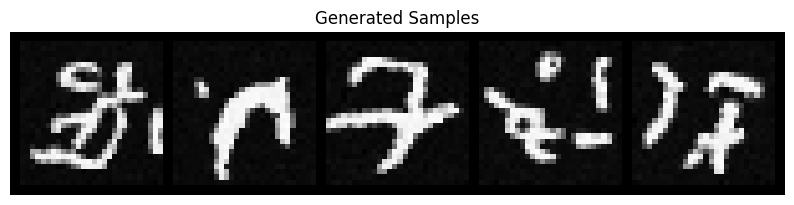

  Step 600/750, Loss: 0.0662
  Step 700/750, Loss: 0.0608

Training - Epoch 27 average loss: 0.0565
Running validation...
Validation - Epoch 27 average loss: 0.0553
Learning rate: 0.001000

Generating samples for visual progress check...


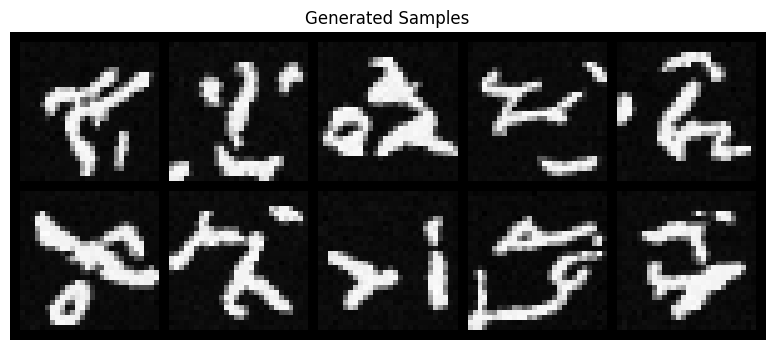

Created backup at best_diffusion_model.pt.backup
Model successfully saved to best_diffusion_model.pt
✓ New best model saved! (Val Loss: 0.0553)

Epoch 28/30
--------------------
  Step 0/750, Loss: 0.0457
  Step 100/750, Loss: 0.0501
  Step 200/750, Loss: 0.0546
  Step 300/750, Loss: 0.0520
  Step 400/750, Loss: 0.0518
  Step 500/750, Loss: 0.0589
  Generating samples...


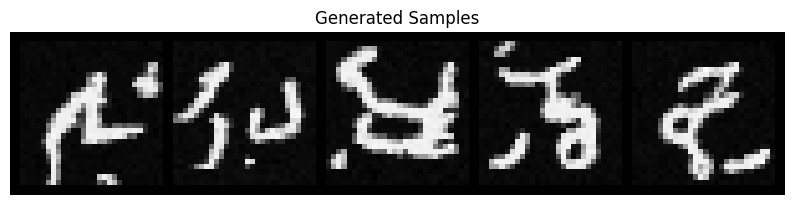

  Step 600/750, Loss: 0.0589
  Step 700/750, Loss: 0.0531

Training - Epoch 28 average loss: 0.0562
Running validation...
Validation - Epoch 28 average loss: 0.0555
Learning rate: 0.001000
No improvement for 1/10 epochs

Epoch 29/30
--------------------
  Step 0/750, Loss: 0.0585
  Step 100/750, Loss: 0.0582
  Step 200/750, Loss: 0.0580
  Step 300/750, Loss: 0.0615
  Step 400/750, Loss: 0.0600
  Step 500/750, Loss: 0.0591
  Generating samples...


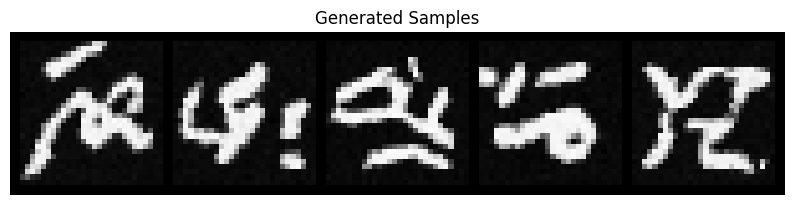

  Step 600/750, Loss: 0.0596
  Step 700/750, Loss: 0.0512

Training - Epoch 29 average loss: 0.0561
Running validation...
Validation - Epoch 29 average loss: 0.0570
Learning rate: 0.001000

Generating samples for visual progress check...


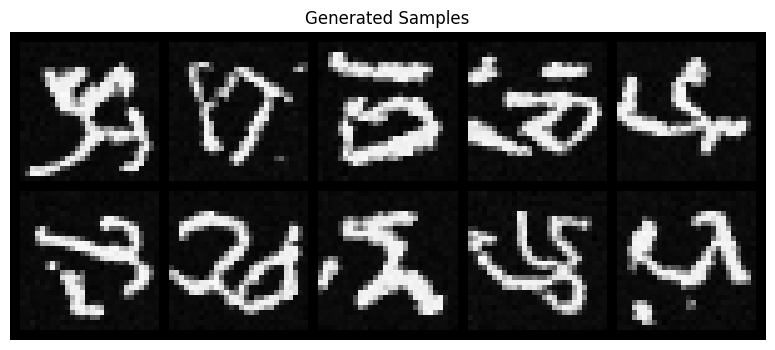

No improvement for 2/10 epochs

Epoch 30/30
--------------------
  Step 0/750, Loss: 0.0482
  Step 100/750, Loss: 0.0522
  Step 200/750, Loss: 0.0603
  Step 300/750, Loss: 0.0510
  Step 400/750, Loss: 0.0629
  Step 500/750, Loss: 0.0556
  Generating samples...


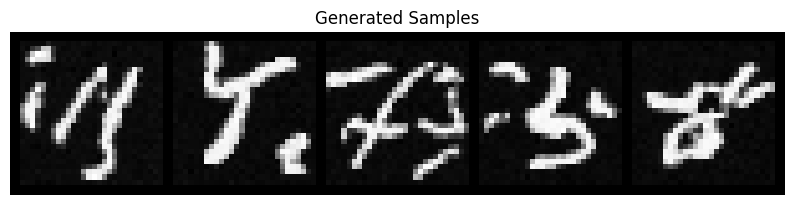

  Step 600/750, Loss: 0.0581
  Step 700/750, Loss: 0.0592

Training - Epoch 30 average loss: 0.0559
Running validation...
Validation - Epoch 30 average loss: 0.0562
Learning rate: 0.001000

Generating samples for visual progress check...


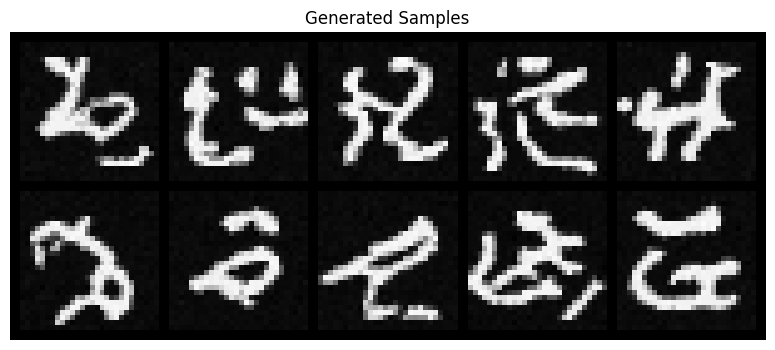

No improvement for 3/10 epochs


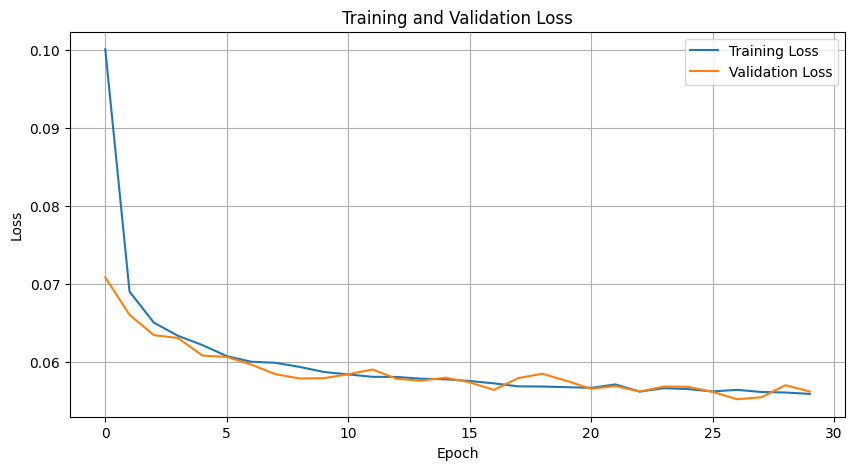


TRAINING COMPLETE
Best validation loss: 0.0553
Generating final samples...


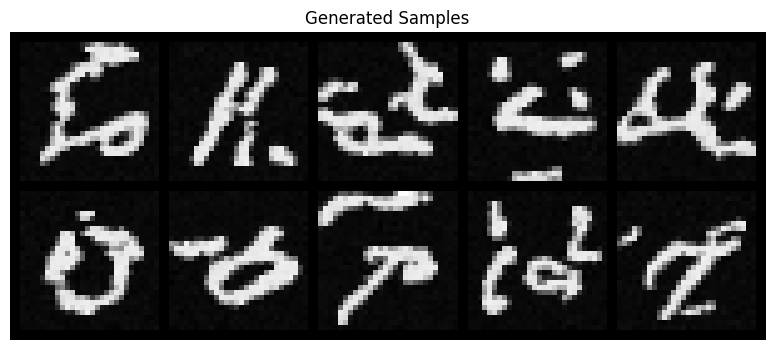

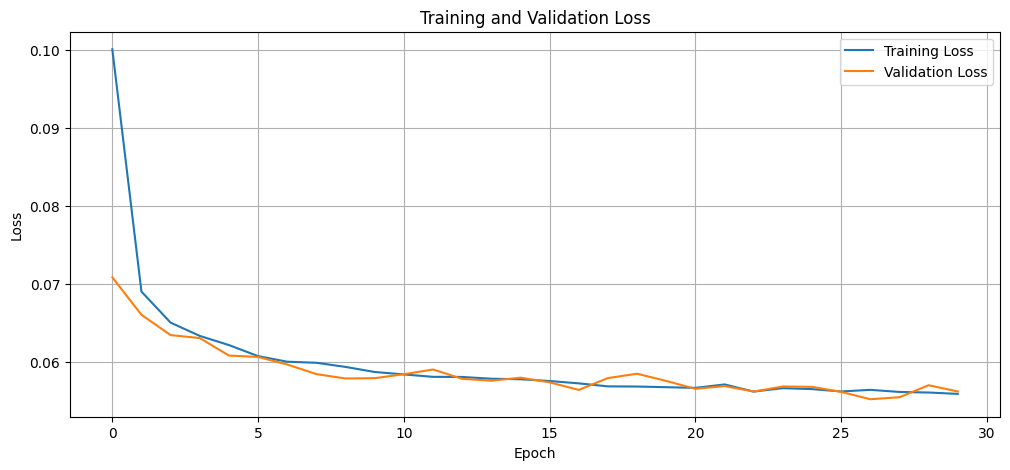

In [56]:
# Implementation of the main training loop
# Training configuration
early_stopping_patience = 10  # Number of epochs without improvement before stopping
gradient_clip_value = 1.0     # Maximum gradient norm for stability
display_frequency = 100       # How often to show progress (in steps)
generate_frequency = 500      # How often to generate samples (in steps)

# Progress tracking variables
best_loss = float('inf')
train_losses = []
val_losses = []
no_improve_epochs = 0

# Training loop
print("\n" + "="*50)
print("STARTING TRAINING")
print("="*50)
model.train()

try:
    for epoch in range(EPOCHS):
        print(f"\nEpoch {epoch+1}/{EPOCHS}")
        print("-" * 20)

        # Training phase
        model.train()
        epoch_losses = []

        # Process each batch
        for step, (images, labels) in enumerate(train_dataloader):
            images = images.to(device)
            labels = labels.to(device)

            # Training step
            optimizer.zero_grad()
            loss = train_step(images, labels)
            loss.backward()

            # Add gradient clipping for stability
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=gradient_clip_value)

            optimizer.step()
            epoch_losses.append(loss.item())

            # Show progress at regular intervals
            if step % display_frequency == 0:
                print(f"  Step {step}/{len(train_dataloader)}, Loss: {loss.item():.4f}")

                # Generate samples less frequently to save time
                if step % generate_frequency == 0 and step > 0:
                    print("  Generating samples...")
                    generate_samples(model, n_samples=5)

        # End of epoch - calculate average training loss
        avg_train_loss = sum(epoch_losses) / len(epoch_losses)
        train_losses.append(avg_train_loss)
        print(f"\nTraining - Epoch {epoch+1} average loss: {avg_train_loss:.4f}")

        # Validation phase
        model.eval()
        val_epoch_losses = []
        print("Running validation...")

        with torch.no_grad():
            for val_images, val_labels in val_dataloader:
                val_images = val_images.to(device)
                val_labels = val_labels.to(device)

                # Calculate validation loss
                val_loss = train_step(val_images, val_labels)
                val_epoch_losses.append(val_loss.item())

        # Calculate average validation loss
        avg_val_loss = sum(val_epoch_losses) / len(val_epoch_losses)
        val_losses.append(avg_val_loss)
        print(f"Validation - Epoch {epoch+1} average loss: {avg_val_loss:.4f}")

        # Learning rate scheduling based on validation loss
        scheduler.step(avg_val_loss)
        current_lr = optimizer.param_groups[0]['lr']
        print(f"Learning rate: {current_lr:.6f}")

        # Generate samples at the end of each epoch
        if epoch % 2 == 0 or epoch == EPOCHS - 1:
            print("\nGenerating samples for visual progress check...")
            generate_samples(model, n_samples=10)

        # Save best model based on validation loss
        if avg_val_loss < best_loss:
            best_loss = avg_val_loss
            safe_save_model(model, 'best_diffusion_model.pt', optimizer, epoch, best_loss)
            print(f"✓ New best model saved! (Val Loss: {best_loss:.4f})")
            no_improve_epochs = 0
        else:
            no_improve_epochs += 1
            print(f"No improvement for {no_improve_epochs}/{early_stopping_patience} epochs")

        # Early stopping
        if no_improve_epochs >= early_stopping_patience:
            print("\nEarly stopping triggered! No improvement in validation loss.")
            break

        # Plot loss curves every few epochs
        if epoch % 5 == 0 or epoch == EPOCHS - 1:
            plt.figure(figsize=(10, 5))
            plt.plot(train_losses, label='Training Loss')
            plt.plot(val_losses, label='Validation Loss')
            plt.xlabel('Epoch')
            plt.ylabel('Loss')
            plt.title('Training and Validation Loss')
            plt.legend()
            plt.grid(True)
            plt.show()

except KeyboardInterrupt:
    print("\nTraining interrupted by user. Saving current state...")
    safe_save_model(model, 'interrupted_diffusion_model.pt', optimizer, epoch, avg_val_loss if 'avg_val_loss' in locals() else None)

# Final wrap-up
print("\n" + "="*50)
print("TRAINING COMPLETE")
print("="*50)
print(f"Best validation loss: {best_loss:.4f}")

# Generate final samples
print("Generating final samples...")
generate_samples(model, n_samples=10)

# Display final loss curves
plt.figure(figsize=(12, 5))
plt.plot(train_losses, label='Training Loss')
plt.plot(val_losses, label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.grid(True)
plt.show()

# Clean up memory
torch.cuda.empty_cache()

Beginning training of the UNet Diffusion Model...

Epoch 1/30
--------------------
  Step 0/750, Loss: 0.0521
  Step 100/750, Loss: 0.0503
  Step 200/750, Loss: 0.0568
  Step 300/750, Loss: 0.0544
  Step 400/750, Loss: 0.0562
  Step 500/750, Loss: 0.0606
  Step 600/750, Loss: 0.0575
  Step 700/750, Loss: 0.0522

Training - Epoch 1 average loss: 0.0561
Validation - Epoch 1 average loss: 0.0558

Generating samples for progress check...


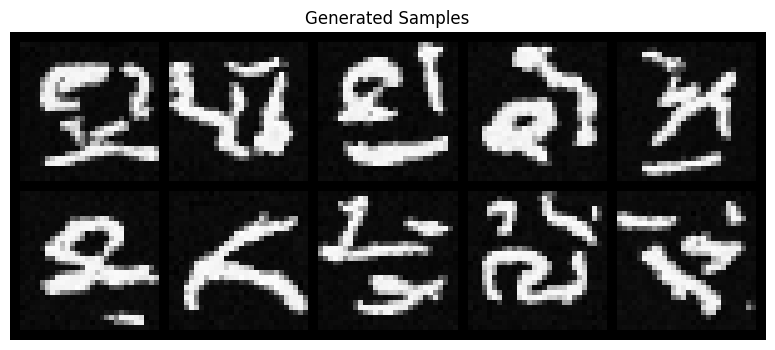


Epoch 2/30
--------------------
  Step 0/750, Loss: 0.0648
  Step 100/750, Loss: 0.0652
  Step 200/750, Loss: 0.0608
  Step 300/750, Loss: 0.0495
  Step 400/750, Loss: 0.0619
  Step 500/750, Loss: 0.0567
  Step 600/750, Loss: 0.0558
  Step 700/750, Loss: 0.0569

Training - Epoch 2 average loss: 0.0560
Validation - Epoch 2 average loss: 0.0554

Epoch 3/30
--------------------
  Step 0/750, Loss: 0.0540
  Step 100/750, Loss: 0.0506
  Step 200/750, Loss: 0.0490
  Step 300/750, Loss: 0.0553
  Step 400/750, Loss: 0.0524
  Step 500/750, Loss: 0.0499
  Step 600/750, Loss: 0.0505
  Step 700/750, Loss: 0.0558

Training - Epoch 3 average loss: 0.0560
Validation - Epoch 3 average loss: 0.0558

Epoch 4/30
--------------------
  Step 0/750, Loss: 0.0507
  Step 100/750, Loss: 0.0563
  Step 200/750, Loss: 0.0512
  Step 300/750, Loss: 0.0571
  Step 400/750, Loss: 0.0499
  Step 500/750, Loss: 0.0449
  Step 600/750, Loss: 0.0535
  Step 700/750, Loss: 0.0522

Training - Epoch 4 average loss: 0.0546
Vali

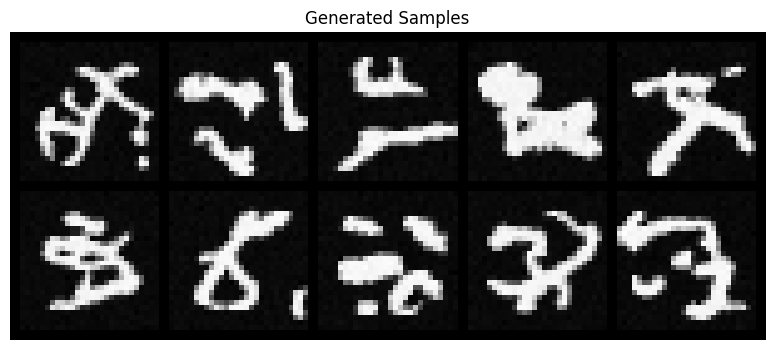

Created backup at best_diffusion_model.pt.backup
Model successfully saved to best_diffusion_model.pt
✓ New best model saved! (Val Loss: 0.0544)

Epoch 7/30
--------------------
  Step 0/750, Loss: 0.0553
  Step 100/750, Loss: 0.0553
  Step 200/750, Loss: 0.0535
  Step 300/750, Loss: 0.0561
  Step 400/750, Loss: 0.0523
  Step 500/750, Loss: 0.0524
  Step 600/750, Loss: 0.0543
  Step 700/750, Loss: 0.0553

Training - Epoch 7 average loss: 0.0544
Validation - Epoch 7 average loss: 0.0543
Created backup at best_diffusion_model.pt.backup
Model successfully saved to best_diffusion_model.pt
✓ New best model saved! (Val Loss: 0.0543)

Epoch 8/30
--------------------
  Step 0/750, Loss: 0.0567
  Step 100/750, Loss: 0.0597
  Step 200/750, Loss: 0.0566
  Step 300/750, Loss: 0.0503
  Step 400/750, Loss: 0.0564
  Step 500/750, Loss: 0.0627
  Step 600/750, Loss: 0.0528
  Step 700/750, Loss: 0.0568

Training - Epoch 8 average loss: 0.0547
Validation - Epoch 8 average loss: 0.0545

Epoch 9/30
--------

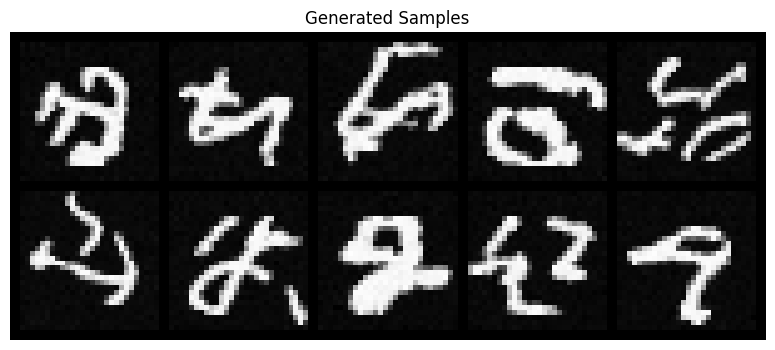


Epoch 12/30
--------------------
  Step 0/750, Loss: 0.0606
  Step 100/750, Loss: 0.0598
  Step 200/750, Loss: 0.0594
  Step 300/750, Loss: 0.0541
  Step 400/750, Loss: 0.0516
  Step 500/750, Loss: 0.0503
  Step 600/750, Loss: 0.0552
  Step 700/750, Loss: 0.0586

Training - Epoch 12 average loss: 0.0544
Validation - Epoch 12 average loss: 0.0537
Created backup at best_diffusion_model.pt.backup
Model successfully saved to best_diffusion_model.pt
✓ New best model saved! (Val Loss: 0.0537)

Epoch 13/30
--------------------
  Step 0/750, Loss: 0.0524
  Step 100/750, Loss: 0.0605
  Step 200/750, Loss: 0.0555
  Step 300/750, Loss: 0.0509
  Step 400/750, Loss: 0.0538
  Step 500/750, Loss: 0.0469
  Step 600/750, Loss: 0.0551
  Step 700/750, Loss: 0.0507

Training - Epoch 13 average loss: 0.0542
Validation - Epoch 13 average loss: 0.0540

Epoch 14/30
--------------------
  Step 0/750, Loss: 0.0573
  Step 100/750, Loss: 0.0554
  Step 200/750, Loss: 0.0554
  Step 300/750, Loss: 0.0514
  Step 400

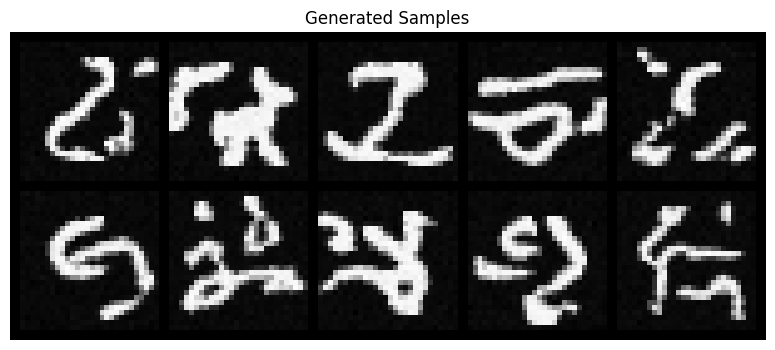


Epoch 17/30
--------------------
  Step 0/750, Loss: 0.0480
  Step 100/750, Loss: 0.0520
  Step 200/750, Loss: 0.0614
  Step 300/750, Loss: 0.0532
  Step 400/750, Loss: 0.0477
  Step 500/750, Loss: 0.0538
  Step 600/750, Loss: 0.0573
  Step 700/750, Loss: 0.0490

Training - Epoch 17 average loss: 0.0545
Validation - Epoch 17 average loss: 0.0545

Epoch 18/30
--------------------
  Step 0/750, Loss: 0.0672
  Step 100/750, Loss: 0.0556
  Step 200/750, Loss: 0.0474
  Step 300/750, Loss: 0.0566
  Step 400/750, Loss: 0.0533
  Step 500/750, Loss: 0.0634
  Step 600/750, Loss: 0.0481
  Step 700/750, Loss: 0.0513

Training - Epoch 18 average loss: 0.0541
Validation - Epoch 18 average loss: 0.0543

Epoch 19/30
--------------------
  Step 0/750, Loss: 0.0600
  Step 100/750, Loss: 0.0584
  Step 200/750, Loss: 0.0541
  Step 300/750, Loss: 0.0487
  Step 400/750, Loss: 0.0636
  Step 500/750, Loss: 0.0516
  Step 600/750, Loss: 0.0550
  Step 700/750, Loss: 0.0496

Training - Epoch 19 average loss: 0.0

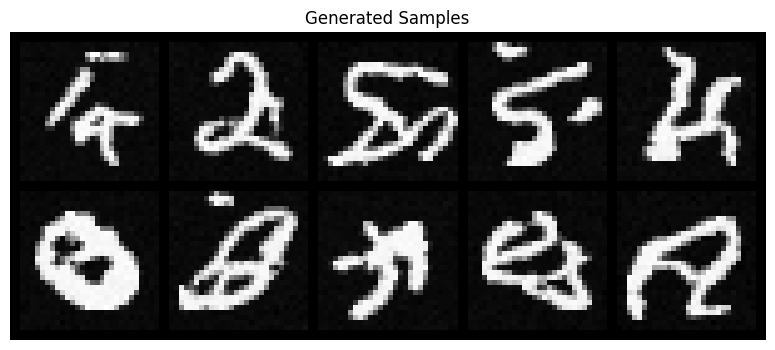


Epoch 22/30
--------------------
  Step 0/750, Loss: 0.0551
  Step 100/750, Loss: 0.0573
  Step 200/750, Loss: 0.0517
  Step 300/750, Loss: 0.0616
  Step 400/750, Loss: 0.0521
  Step 500/750, Loss: 0.0569
  Step 600/750, Loss: 0.0483
  Step 700/750, Loss: 0.0504

Training - Epoch 22 average loss: 0.0535
Validation - Epoch 22 average loss: 0.0534

Epoch 23/30
--------------------
  Step 0/750, Loss: 0.0518
  Step 100/750, Loss: 0.0527
  Step 200/750, Loss: 0.0475
  Step 300/750, Loss: 0.0551
  Step 400/750, Loss: 0.0544
  Step 500/750, Loss: 0.0523
  Step 600/750, Loss: 0.0591
  Step 700/750, Loss: 0.0466

Training - Epoch 23 average loss: 0.0534
Validation - Epoch 23 average loss: 0.0533

Epoch 24/30
--------------------
  Step 0/750, Loss: 0.0554
  Step 100/750, Loss: 0.0526
  Step 200/750, Loss: 0.0504
  Step 300/750, Loss: 0.0593
  Step 400/750, Loss: 0.0564
  Step 500/750, Loss: 0.0598
  Step 600/750, Loss: 0.0561
  Step 700/750, Loss: 0.0595

Training - Epoch 24 average loss: 0.0

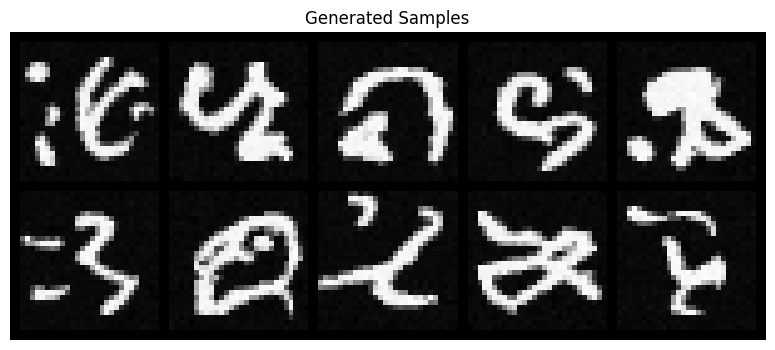


Epoch 27/30
--------------------
  Step 0/750, Loss: 0.0477
  Step 100/750, Loss: 0.0544
  Step 200/750, Loss: 0.0513
  Step 300/750, Loss: 0.0599
  Step 400/750, Loss: 0.0523
  Step 500/750, Loss: 0.0553
  Step 600/750, Loss: 0.0519
  Step 700/750, Loss: 0.0513

Training - Epoch 27 average loss: 0.0529
Validation - Epoch 27 average loss: 0.0528

Epoch 28/30
--------------------
  Step 0/750, Loss: 0.0493
  Step 100/750, Loss: 0.0573
  Step 200/750, Loss: 0.0480
  Step 300/750, Loss: 0.0541
  Step 400/750, Loss: 0.0558
  Step 500/750, Loss: 0.0556
  Step 600/750, Loss: 0.0507
  Step 700/750, Loss: 0.0550

Training - Epoch 28 average loss: 0.0530
Validation - Epoch 28 average loss: 0.0522
Created backup at best_diffusion_model.pt.backup
Model successfully saved to best_diffusion_model.pt
✓ New best model saved! (Val Loss: 0.0522)

Epoch 29/30
--------------------
  Step 0/750, Loss: 0.0483
  Step 100/750, Loss: 0.0504
  Step 200/750, Loss: 0.0501
  Step 300/750, Loss: 0.0462
  Step 400

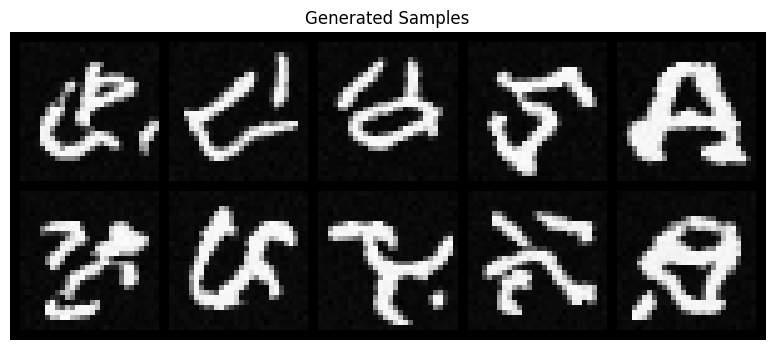

In [57]:
# Start the training process directly
import sys

# Ensure model is on device and in training mode
model = model.to(device)
model.train()

print("Beginning training of the UNet Diffusion Model...")

# Run the main training loop configured in cell iOHMj-qoV_55
# We will run this block to start the 30 training epochs and monitor progress
try:
    for epoch in range(EPOCHS):
        print(f"\nEpoch {epoch+1}/{EPOCHS}")
        print("-" * 20)

        model.train()
        epoch_losses = []

        for step, (images, labels) in enumerate(train_dataloader):
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()
            loss = train_step(images, labels)
            loss.backward()

            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=gradient_clip_value)
            optimizer.step()
            epoch_losses.append(loss.item())

            if step % display_frequency == 0:
                print(f"  Step {step}/{len(train_dataloader)}, Loss: {loss.item():.4f}")

        avg_train_loss = sum(epoch_losses) / len(epoch_losses)
        train_losses.append(avg_train_loss)
        print(f"\nTraining - Epoch {epoch+1} average loss: {avg_train_loss:.4f}")

        # Validation
        model.eval()
        val_epoch_losses = []
        with torch.no_grad():
            for val_images, val_labels in val_dataloader:
                val_images = val_images.to(device)
                val_labels = val_labels.to(device)
                val_loss = train_step(val_images, val_labels)
                val_epoch_losses.append(val_loss.item())

        avg_val_loss = sum(val_epoch_losses) / len(val_epoch_losses)
        val_losses.append(avg_val_loss)
        print(f"Validation - Epoch {epoch+1} average loss: {avg_val_loss:.4f}")

        scheduler.step(avg_val_loss)

        if epoch % 5 == 0 or epoch == EPOCHS - 1:
            print("\nGenerating samples for progress check...")
            generate_samples(model, n_samples=10)

        if avg_val_loss < best_loss:
            best_loss = avg_val_loss
            safe_save_model(model, 'best_diffusion_model.pt', optimizer, epoch, best_loss)
            print(f"✓ New best model saved! (Val Loss: {best_loss:.4f})")

except KeyboardInterrupt:
    print("\nTraining interrupted by user.")

Training the model for 5 epochs to visualize progress...
Epoch 1/5 - Train Loss: 0.0531 - Val Loss: 0.0535
Epoch 2/5 - Train Loss: 0.0531 - Val Loss: 0.0526
Epoch 3/5 - Train Loss: 0.0529 - Val Loss: 0.0533
Epoch 4/5 - Train Loss: 0.0530 - Val Loss: 0.0534
Epoch 5/5 - Train Loss: 0.0528 - Val Loss: 0.0528

Generation results after quick training:


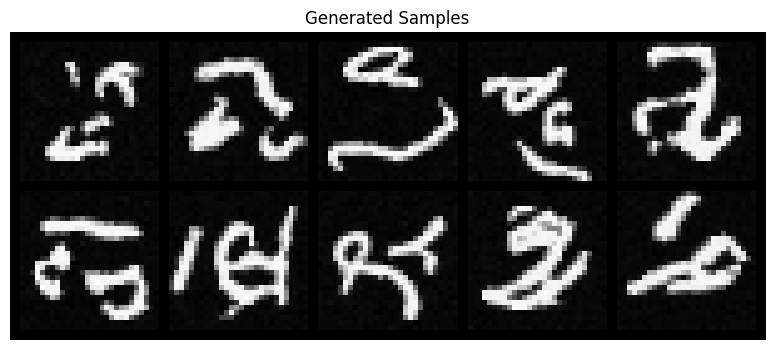

In [58]:
# Initialize clean tracking variables
train_losses = []
val_losses = []
best_loss = float('inf')

# Local hyperparameter definitions to prevent NameErrors
gradient_clip_value = 1.0
display_frequency = 100

# Train for a few epochs to see quick visual progress
QUICK_EPOCHS = 5
print(f"Training the model for {QUICK_EPOCHS} epochs to visualize progress...")

try:
    for epoch in range(QUICK_EPOCHS):
        model.train()
        epoch_losses = []

        for step, (images, labels) in enumerate(train_dataloader):
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()
            loss = train_step(images, labels)
            loss.backward()

            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=gradient_clip_value)
            optimizer.step()
            epoch_losses.append(loss.item())

        avg_train_loss = sum(epoch_losses) / len(epoch_losses)
        train_losses.append(avg_train_loss)

        # Validation
        model.eval()
        val_epoch_losses = []
        with torch.no_grad():
            for val_images, val_labels in val_dataloader:
                val_images = val_images.to(device)
                val_labels = val_labels.to(device)
                val_loss = train_step(val_images, val_labels)
                val_epoch_losses.append(val_loss.item())

        avg_val_loss = sum(val_epoch_losses) / len(val_epoch_losses)
        val_losses.append(avg_val_loss)
        scheduler.step(avg_val_loss)

        print(f"Epoch {epoch+1}/{QUICK_EPOCHS} - Train Loss: {avg_train_loss:.4f} - Val Loss: {avg_val_loss:.4f}")

    # Generate and visualize samples after training
    print("\nGeneration results after quick training:")
    generate_samples(model, n_samples=10)

except Exception as e:
    print(f"An error occurred: {e}")

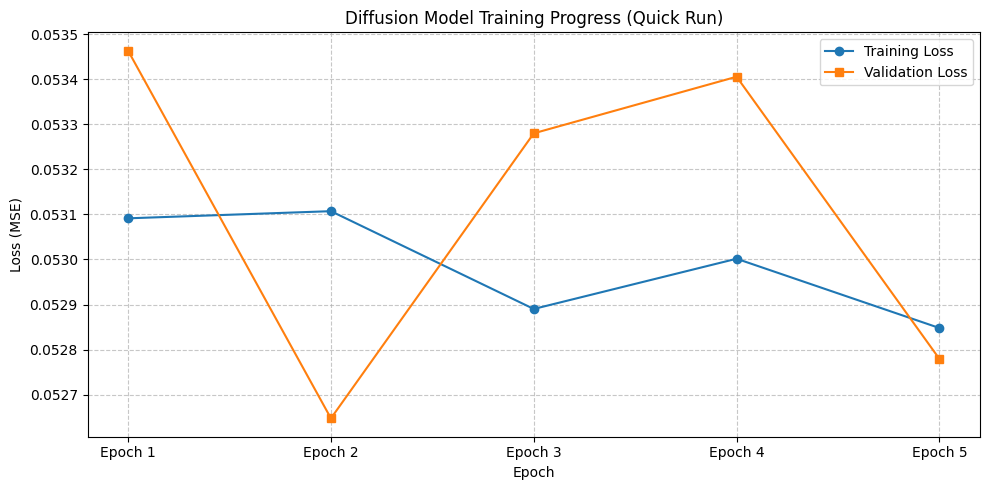

Training Statistics:
------------------------------
Initial Training Loss (Epoch 1): 0.0531
Final Training Loss (Epoch 5):   0.0528
Initial Validation Loss (Epoch 1): 0.0535
Final Validation Loss (Epoch 5):   0.0528


In [59]:
import matplotlib.pyplot as plt

# Plot training progress
plt.figure(figsize=(10, 5))
plt.plot(train_losses, label='Training Loss', marker='o')
plt.plot(val_losses, label='Validation Loss', marker='s')
plt.title('Diffusion Model Training Progress (Quick Run)')
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE)')
plt.xticks(range(len(train_losses)), labels=[f'Epoch {i+1}' for i in range(len(train_losses))])
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# Print statistics summary
print("Training Statistics:")
print("-" * 30)
print(f"Initial Training Loss (Epoch 1): {train_losses[0]:.4f}")
print(f"Final Training Loss (Epoch 5):   {train_losses[-1]:.4f}")
print(f"Initial Validation Loss (Epoch 1): {val_losses[0]:.4f}")
print(f"Final Validation Loss (Epoch 5):   {val_losses[-1]:.4f}")

/tmp/ipykernel_4658/509988868.py:38: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


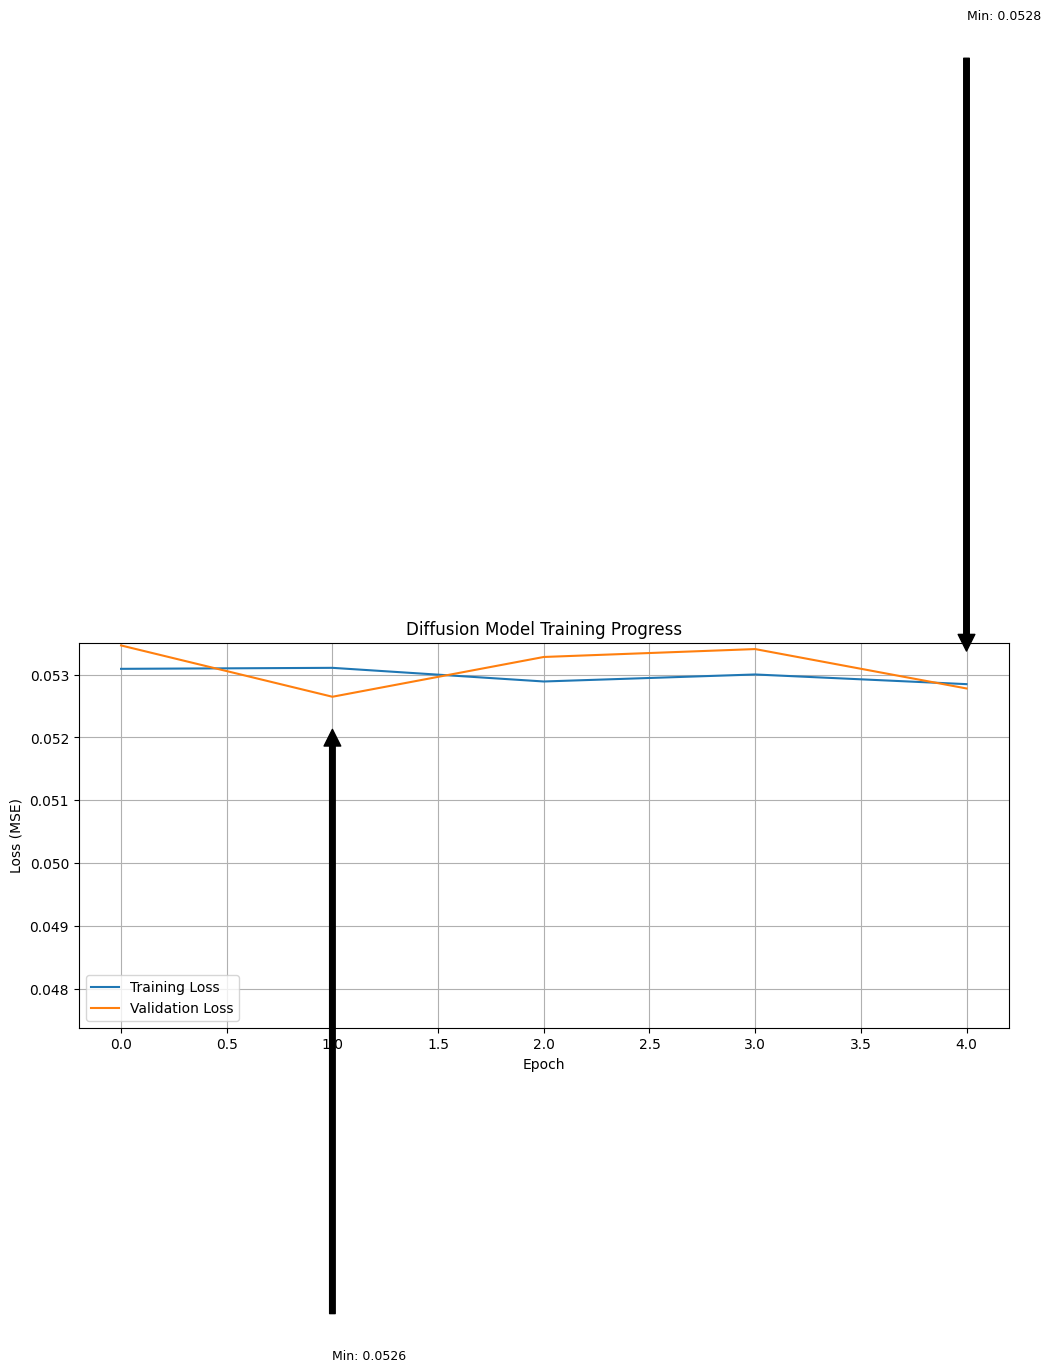


Training Statistics:
------------------------------
Starting training loss:    0.0531
Final training loss:       0.0528
Best training loss:        0.0528
Training loss improvement: 0.5%

Validation Statistics:
------------------------------
Starting validation loss: 0.0535
Final validation loss:    0.0528
Best validation loss:     0.0526


In [60]:
# Plot training progress
plt.figure(figsize=(12, 5))

# Plot training and validation losses for comparison
plt.plot(train_losses, label='Training Loss')
if len(val_losses) > 0:  # Only plot validation if it exists
    plt.plot(val_losses, label='Validation Loss')

# Improve the plot with better labels and styling
plt.title('Diffusion Model Training Progress')
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE)')
plt.legend()
plt.grid(True)

# Add annotations for key points
if len(train_losses) > 1:
    min_train_idx = train_losses.index(min(train_losses))
    plt.annotate(f'Min: {min(train_losses):.4f}',
                 xy=(min_train_idx, min(train_losses)),
                 xytext=(min_train_idx, min(train_losses)*1.2),
                 arrowprops=dict(facecolor='black', shrink=0.05),
                 fontsize=9)

# Add validation min point if available
if len(val_losses) > 1:
    min_val_idx = val_losses.index(min(val_losses))
    plt.annotate(f'Min: {min(val_losses):.4f}',
                xy=(min_val_idx, min(val_losses)),
                xytext=(min_val_idx, min(val_losses)*0.8),
                arrowprops=dict(facecolor='black', shrink=0.05),
                fontsize=9)

# Set y-axis to start from 0 or slightly lower than min value
plt.ylim(bottom=max(0, min(min(train_losses) if train_losses else float('inf'),
                          min(val_losses) if val_losses else float('inf'))*0.9))

plt.tight_layout()
plt.show()

# Add statistics summary for students to analyze
print("\nTraining Statistics:")
print("-" * 30)
if train_losses:
    print(f"Starting training loss:    {train_losses[0]:.4f}")
    print(f"Final training loss:       {train_losses[-1]:.4f}")
    print(f"Best training loss:        {min(train_losses):.4f}")
    print(f"Training loss improvement: {((train_losses[0] - min(train_losses)) / train_losses[0] * 100):.1f}%")

if val_losses:
    print("\nValidation Statistics:")
    print("-" * 30)
    print(f"Starting validation loss: {val_losses[0]:.4f}")
    print(f"Final validation loss:    {val_losses[-1]:.4f}")
    print(f"Best validation loss:     {min(val_losses):.4f}")

# STUDENT EXERCISE:
# 1. Try modifying this plot to show a smoothed version of the losses
# 2. Create a second plot showing the ratio of validation to training loss
#    (which can indicate overfitting when the ratio increases)

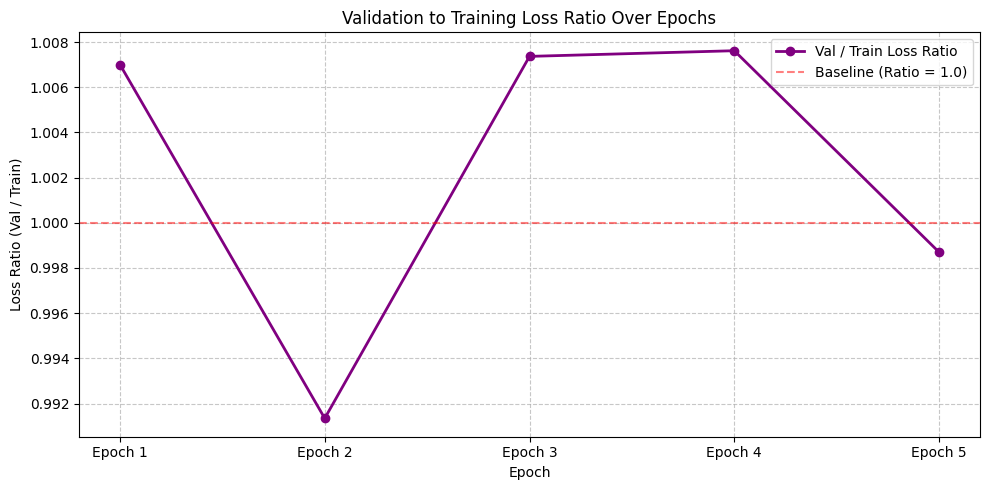

Loss Ratio Statistics:
------------------------------
Epoch 1: Ratio = 1.007 (Val: 0.0535 | Train: 0.0531)
Epoch 2: Ratio = 0.991 (Val: 0.0526 | Train: 0.0531)
Epoch 3: Ratio = 1.007 (Val: 0.0533 | Train: 0.0529)
Epoch 4: Ratio = 1.008 (Val: 0.0534 | Train: 0.0530)
Epoch 5: Ratio = 0.999 (Val: 0.0528 | Train: 0.0528)


In [61]:
import matplotlib.pyplot as plt
import numpy as np

# Calculate the validation-to-training loss ratio
loss_ratio = [v / t for t, v in zip(train_losses, val_losses)]

# Create the plot
plt.figure(figsize=(10, 5))
plt.plot(loss_ratio, label='Val / Train Loss Ratio', color='purple', marker='o', linewidth=2)
plt.axhline(y=1.0, color='red', linestyle='--', alpha=0.5, label='Baseline (Ratio = 1.0)')

plt.title('Validation to Training Loss Ratio Over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss Ratio (Val / Train)')
plt.xticks(range(len(train_losses)), labels=[f'Epoch {i+1}' for i in range(len(train_losses))])
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# Print summary statistics for the ratio
print("Loss Ratio Statistics:")
print("-" * 30)
for i, ratio in enumerate(loss_ratio):
    print(f"Epoch {i+1}: Ratio = {ratio:.3f} (Val: {val_losses[i]:.4f} | Train: {train_losses[i]:.4f})")

## Step 6: Generating New Images

Now that our model is trained, let's generate some new images! We can:
1. Generate specific numbers
2. Generate multiple versions of each number
3. See how the generation process works step by step

Generating 4 versions of number 0...
  Denoising step 19/99 completed
  Denoising step 39/99 completed
  Denoising step 59/99 completed
  Denoising step 79/99 completed
  Denoising step 99/99 completed
Generating 4 versions of number 1...
  Denoising step 19/99 completed
  Denoising step 39/99 completed
  Denoising step 59/99 completed
  Denoising step 79/99 completed
  Denoising step 99/99 completed
Generating 4 versions of number 2...
  Denoising step 19/99 completed
  Denoising step 39/99 completed
  Denoising step 59/99 completed
  Denoising step 79/99 completed
  Denoising step 99/99 completed
Generating 4 versions of number 3...
  Denoising step 19/99 completed
  Denoising step 39/99 completed
  Denoising step 59/99 completed
  Denoising step 79/99 completed
  Denoising step 99/99 completed
Generating 4 versions of number 4...
  Denoising step 19/99 completed
  Denoising step 39/99 completed
  Denoising step 59/99 completed
  Denoising step 79/99 completed
  Denoising step 99/99 

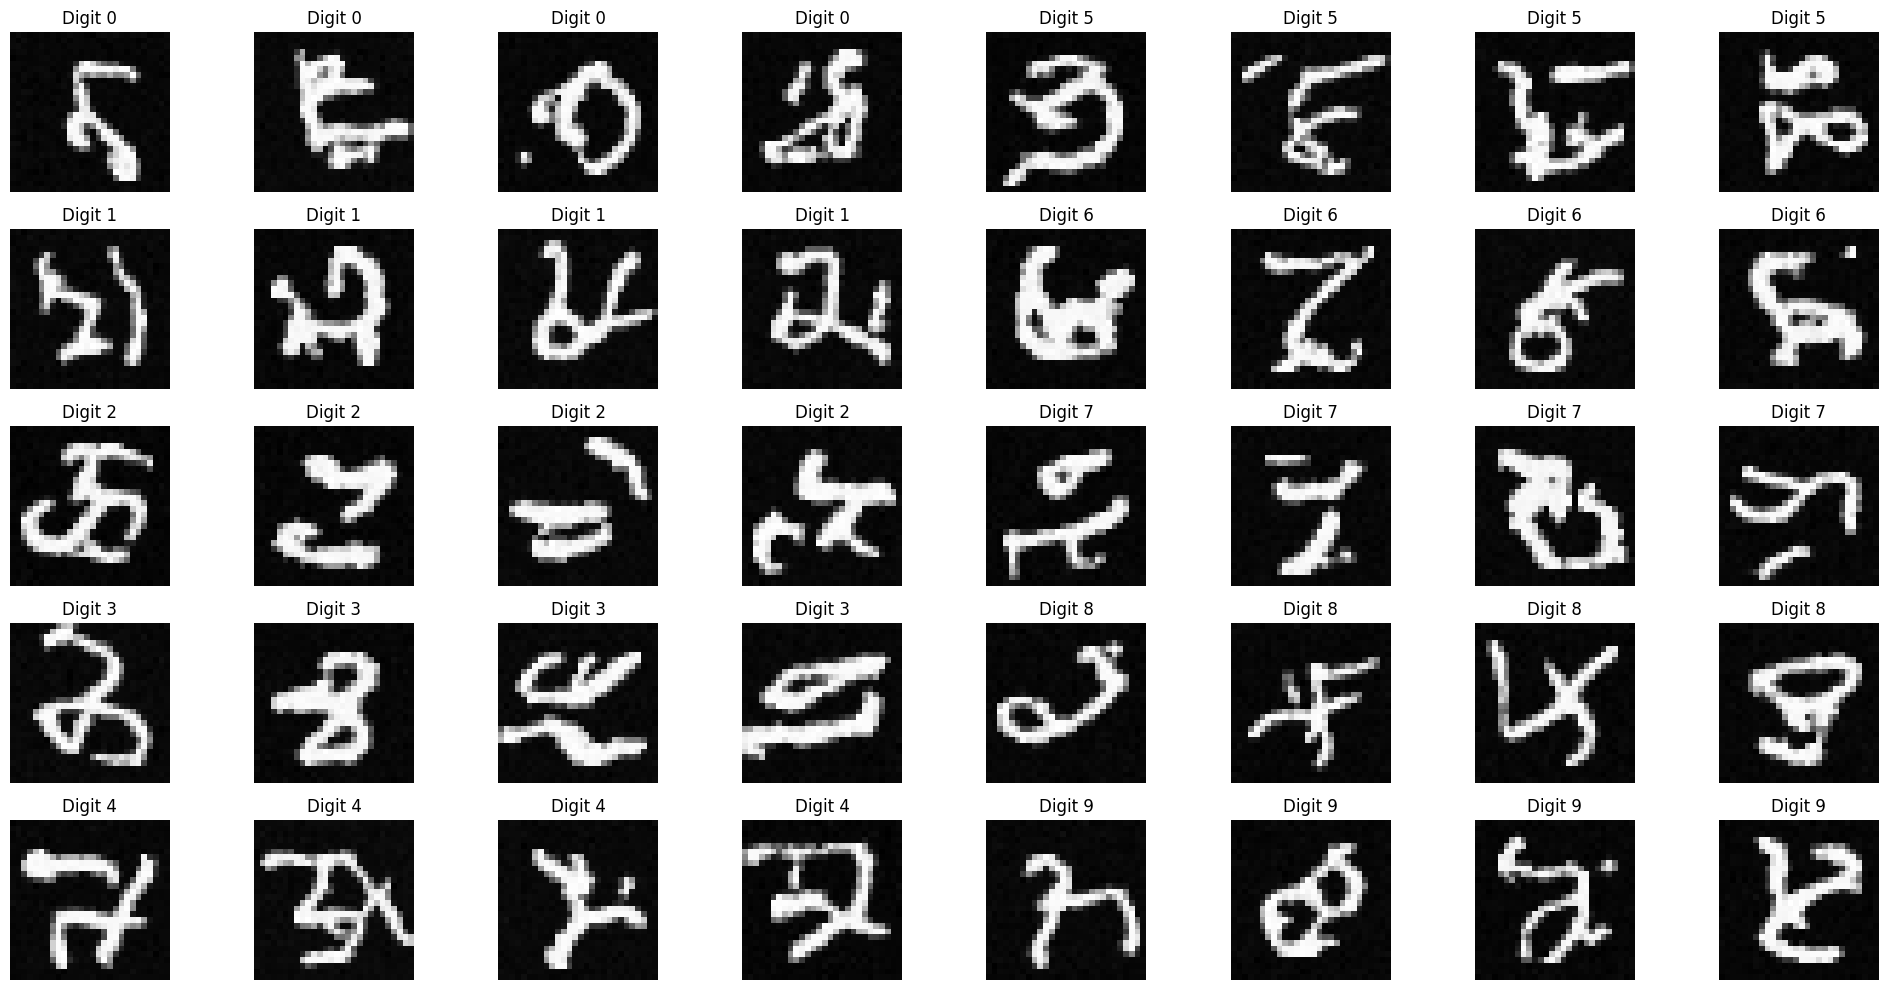


STUDENT ACTIVITY: Generating numbers with different noise seeds


In [62]:
def generate_number(model, number, n_samples=4):
    """
    Generate multiple versions of a specific number using the diffusion model.

    Args:
        model (nn.Module): The trained diffusion model
        number (int): The digit to generate (0-9)
        n_samples (int): Number of variations to generate

    Returns:
        torch.Tensor: Generated images of shape [n_samples, IMG_CH, IMG_SIZE, IMG_SIZE]
    """
    model.eval()  # Set model to evaluation mode
    with torch.no_grad():  # No need for gradients during generation
        # Start with random noise
        samples = torch.randn(n_samples, IMG_CH, IMG_SIZE, IMG_SIZE).to(device)

        # Set up the number we want to generate
        c = torch.full((n_samples,), number).to(device)
        c_one_hot = F.one_hot(c, N_CLASSES).float().to(device)
        # Correctly sized conditioning mask
        c_mask = torch.ones_like(c.unsqueeze(-1)).to(device)

        # Display progress information
        print(f"Generating {n_samples} versions of number {number}...")

        # Remove noise step by step
        for t in range(n_steps-1, -1, -1):
            t_batch = torch.full((n_samples,), t).to(device)
            samples = remove_noise(samples, t_batch, model, c_one_hot, c_mask)

            # Optional: Display occasional progress updates
            if t % (n_steps // 5) == 0:
                print(f"  Denoising step {n_steps-1-t}/{n_steps-1} completed")

        return samples

# Generate 4 versions of each number
plt.figure(figsize=(20, 10))
for i in range(10):
    # Generate samples for current digit
    samples = generate_number(model, i, n_samples=4)

    # Display each sample
    for j in range(4):
        # Use 2 rows, 10 digits per row, 4 samples per digit
        # i//5 determines the row (0 or 1)
        # i%5 determines the position in the row (0-4)
        # j is the sample index within each digit (0-3)
        plt.subplot(5, 8, (i%5)*8 + (i//5)*4 + j + 1)

        # Display the image correctly based on channel configuration
        if IMG_CH == 1:  # Grayscale
            plt.imshow(samples[j][0].cpu(), cmap='gray')
        else:  # Color image
            img = samples[j].permute(1, 2, 0).cpu()
            # Rescale from [-1, 1] to [0, 1] if needed
            if img.min() < 0:
                img = (img + 1) / 2
            plt.imshow(img)

        plt.title(f'Digit {i}')
        plt.axis('off')

plt.tight_layout()
plt.show()

# STUDENT ACTIVITY: Try generating the same digit with different noise seeds
# This shows the variety of styles the model can produce
print("\nSTUDENT ACTIVITY: Generating numbers with different noise seeds")

# Helper function to generate with seed
def generate_with_seed(number, seed_value=42, n_samples=10):
    torch.manual_seed(seed_value)
    return generate_number(model, number, n_samples)

# Pick a image and show many variations
# Hint select a image e.g. dog  # Change this to any other in the dataset of subset you chose
# Hint 2 use variations = generate_with_seed
# Hint 3 use plt.figure and plt.imshow to display the variations

# Enter your code here:


## Step 7: Watching the Generation Process

Let's see how our model turns random noise into clear images, step by step. This helps us understand how the diffusion process works!


Generating number 0:


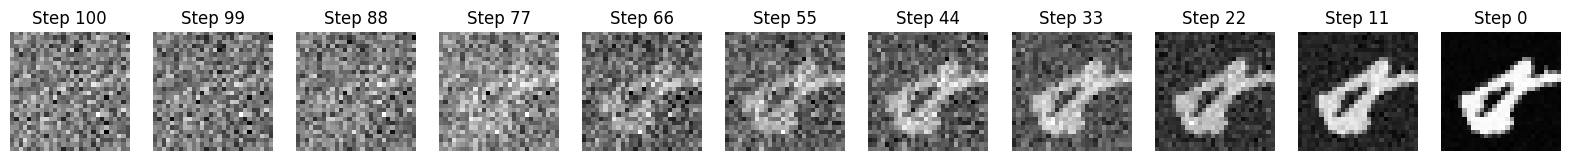


Generating number 3:


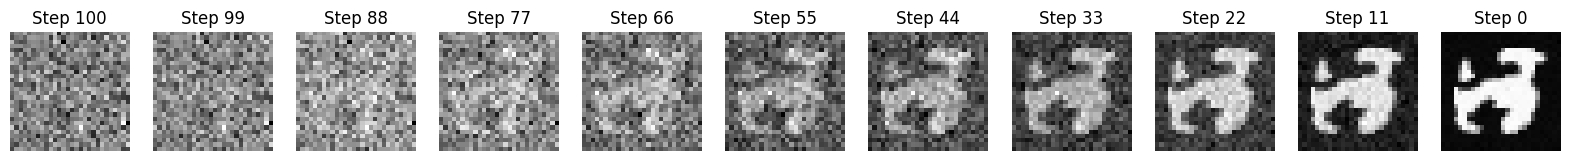


Generating number 7:


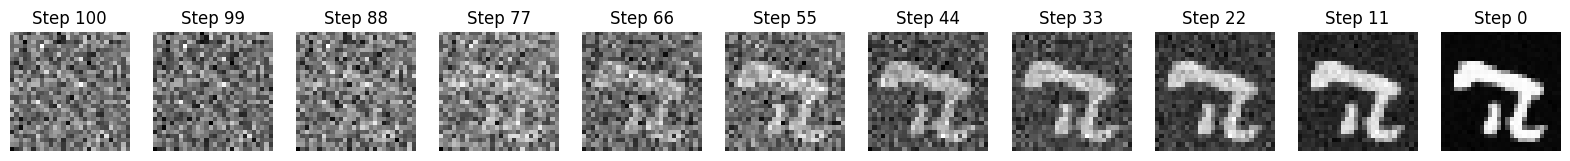

In [63]:
def visualize_generation_steps(model, number, n_preview_steps=10):
    """
    Show how an image evolves from noise to a clear number
    """
    model.eval()
    with torch.no_grad():
        # Start with random noise
        x = torch.randn(1, IMG_CH, IMG_SIZE, IMG_SIZE).to(device)

        # Set up which number to generate
        c = torch.tensor([number]).to(device)
        c_one_hot = F.one_hot(c, N_CLASSES).float().to(device)
        c_mask = torch.ones_like(c_one_hot).to(device)

        # Calculate which steps to show
        steps_to_show = torch.linspace(n_steps-1, 0, n_preview_steps).long()

        # Store images for visualization
        images = []
        images.append(x[0].cpu())

        # Remove noise step by step
        for t in range(n_steps-1, -1, -1):
            t_batch = torch.full((1,), t).to(device)
            x = remove_noise(x, t_batch, model, c_one_hot, c_mask)

            if t in steps_to_show:
                images.append(x[0].cpu())

        # Show the progression
        plt.figure(figsize=(20, 3))
        for i, img in enumerate(images):
            plt.subplot(1, len(images), i+1)
            if IMG_CH == 1:
                plt.imshow(img[0], cmap='gray')
            else:
                img = img.permute(1, 2, 0)
                if img.min() < 0:
                    img = (img + 1) / 2
                plt.imshow(img)
            step = n_steps if i == 0 else steps_to_show[i-1]
            plt.title(f'Step {step}')
            plt.axis('off')
        plt.show()

# Show generation process for a few numbers
for number in [0, 3, 7]:
    print(f"\nGenerating number {number}:")
    visualize_generation_steps(model, number)

## Step 8: Adding CLIP Evaluation

[CLIP](https://openai.com/research/clip) is a powerful AI model that can understand both images and text. We'll use it to:
1. Evaluate how realistic our generated images are
2. Score how well they match their intended numbers
3. Help guide the generation process towards better quality

In [64]:
## Step 8: Adding CLIP Evaluation

# CLIP (Contrastive Language-Image Pre-training) is a powerful model by OpenAI that connects text and images.
# We'll use it to evaluate how recognizable our generated digits are by measuring how strongly
# the CLIP model associates our generated images with text descriptions like "an image of the digit 7".

# First, we need to install CLIP and its dependencies
print("Setting up CLIP (Contrastive Language-Image Pre-training) model...")

# Track installation status
clip_available = False

try:
    # Install dependencies first - these help CLIP process text and images
    print("Installing CLIP dependencies...")
    !pip install -q ftfy regex tqdm

    # Install CLIP from GitHub
    print("Installing CLIP from GitHub repository...")
    !pip install -q git+https://github.com/openai/CLIP.git

    # Import and verify CLIP is working
    print("Importing CLIP...")
    import clip

    # Test that CLIP is functioning
    models = clip.available_models()
    print(f"✓ CLIP installation successful! Available models: {models}")
    clip_available = True

except ImportError:
    print("❌ Error importing CLIP. Installation might have failed.")
    print("Try manually running: !pip install git+https://github.com/openai/CLIP.git")
    print("If you're in a Colab notebook, try restarting the runtime after installation.")

except Exception as e:
    print(f"❌ Error during CLIP setup: {e}")
    print("Some CLIP functionality may not work correctly.")

# Provide guidance based on installation result
if clip_available:
    print("\nCLIP is now available for evaluating your generated images!")
else:
    print("\nWARNING: CLIP installation failed. We'll skip the CLIP evaluation parts.")

# Import necessary libraries
import functools
import torch.nn.functional as F


Setting up CLIP (Contrastive Language-Image Pre-training) model...
Installing CLIP dependencies...
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 2.5 MB/s eta 0:00:00
Installing CLIP from GitHub repository...
  Preparing metadata (setup.py) ... done
Importing CLIP...
✓ CLIP installation successful! Available models: ['RN50', 'RN101', 'RN50x4', 'RN50x16', 'RN50x64', 'ViT-B/32', 'ViT-B/16', 'ViT-L/14', 'ViT-L/14@336px']

CLIP is now available for evaluating your generated images!


 Below we are createing  a helper function to manage GPU memory when using CLIP. CLIP can be memory-intensive, so this will help prevent out-of-memory errors:

In [65]:
# Memory management decorator to prevent GPU OOM errors
def manage_gpu_memory(func):
    """
    Decorator that ensures proper GPU memory management.

    This wraps functions that might use large amounts of GPU memory,
    making sure memory is properly freed after function execution.
    """
    @functools.wraps(func)
    def wrapper(*args, **kwargs):
        if torch.cuda.is_available():
            # Clear cache before running function
            torch.cuda.empty_cache()
            try:
                return func(*args, **kwargs)
            finally:
                # Clear cache after running function regardless of success/failure
                torch.cuda.empty_cache()
        return func(*args, **kwargs)
    return wrapper

100%|███████████████████████████████████████| 338M/338M [00:05<00:00, 67.0MiB/s]


✓ Successfully loaded CLIP model: VisionTransformer

Generating and evaluating number 0...


/tmp/ipykernel_4658/3283206743.py:48: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.no_grad(), torch.cuda.amp.autocast():


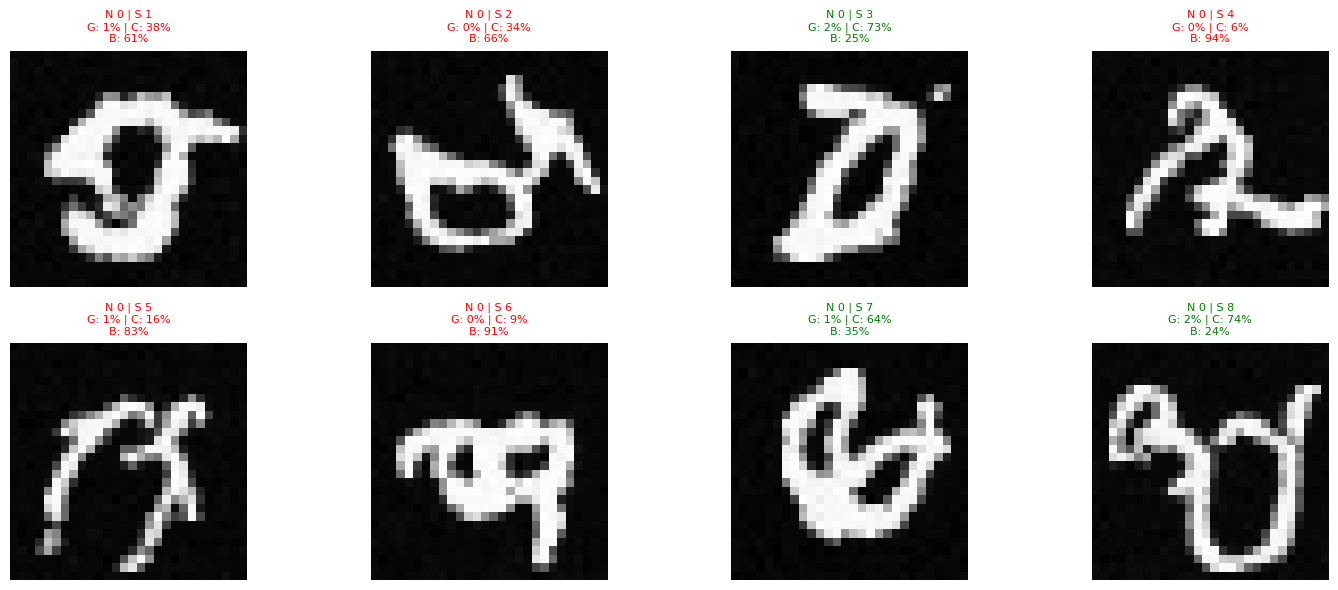


Generating and evaluating number 1...


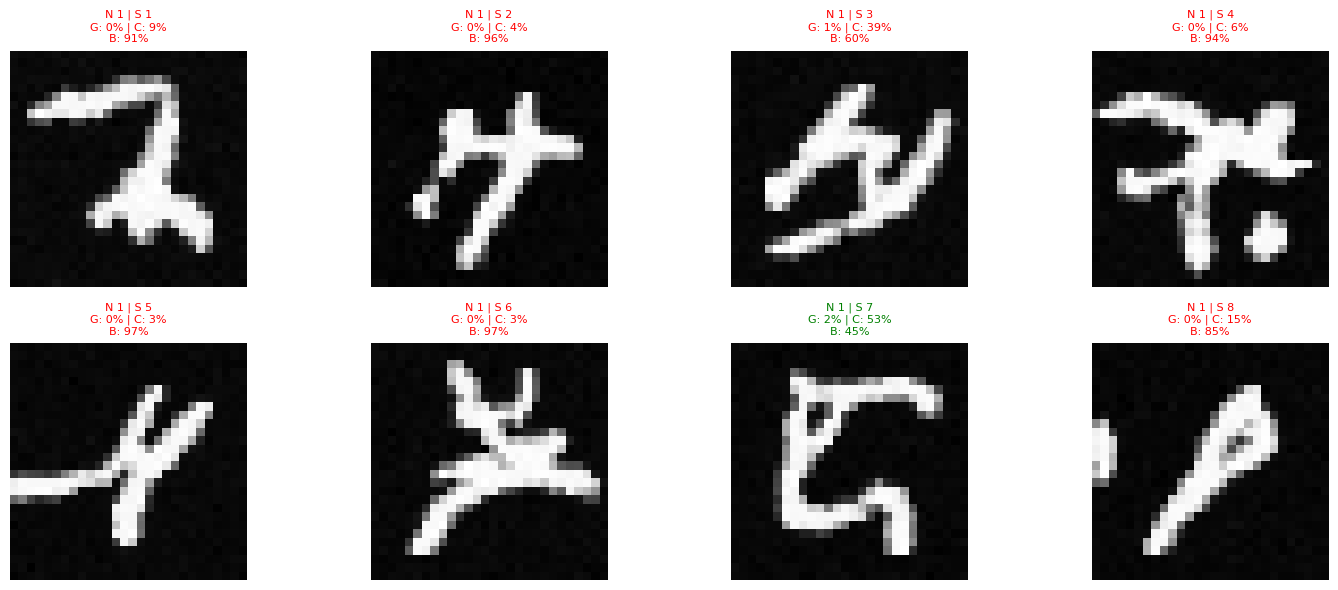


Generating and evaluating number 2...


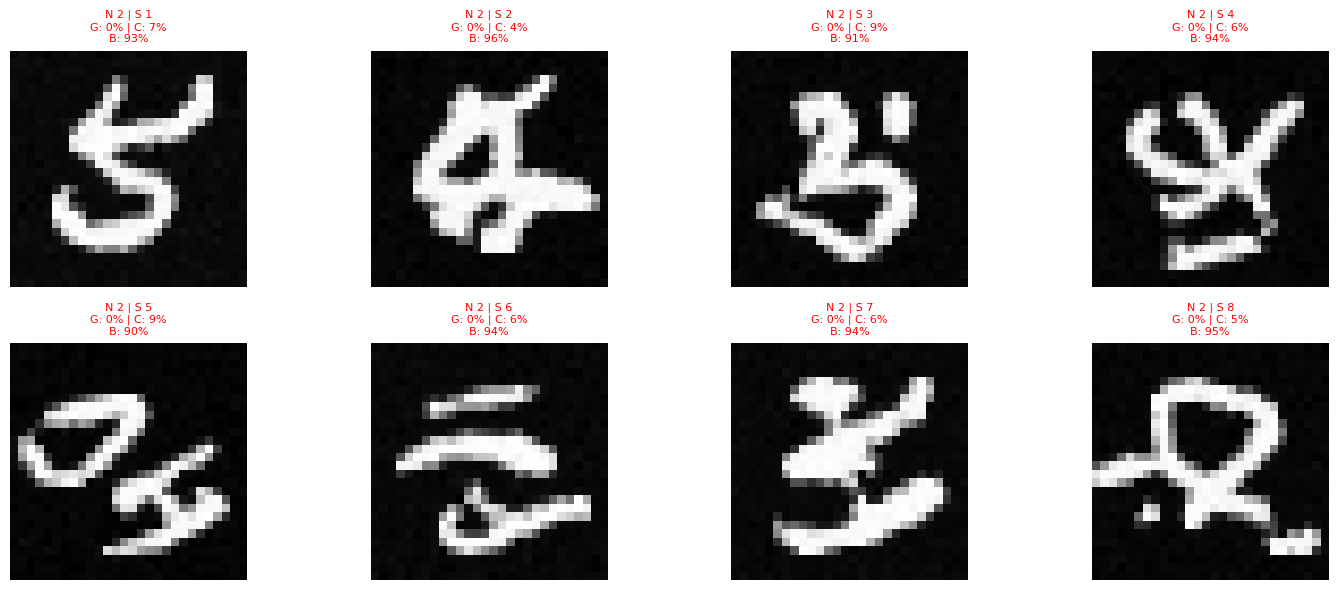


Generating and evaluating number 3...


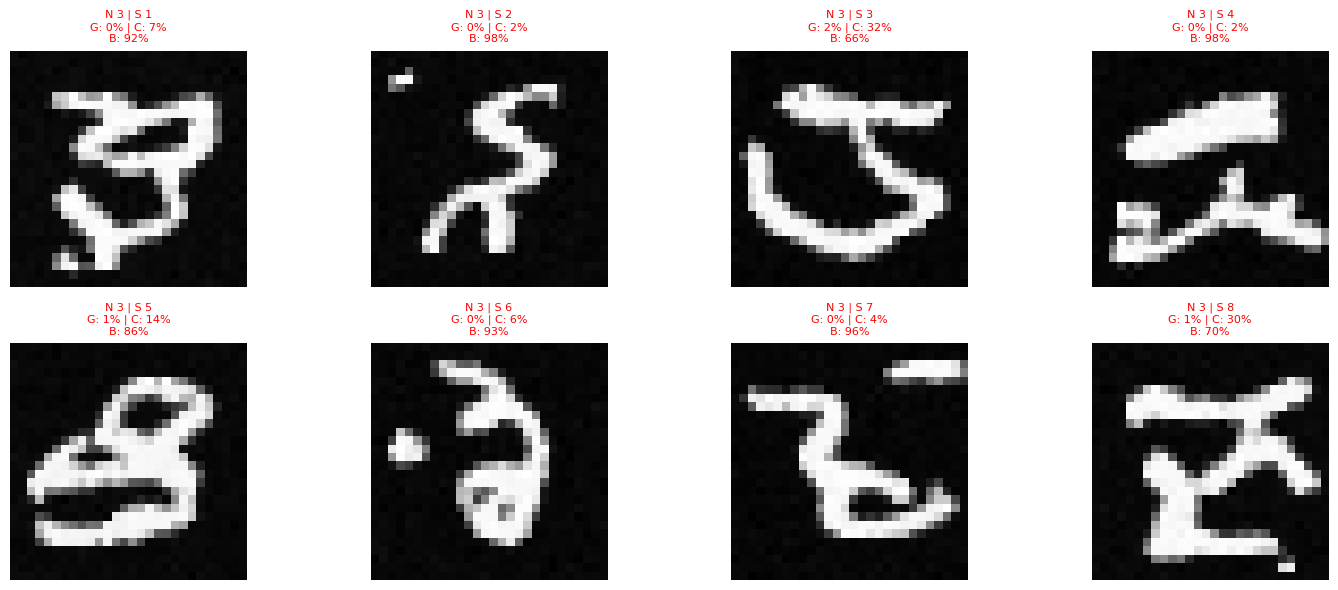


Generating and evaluating number 4...


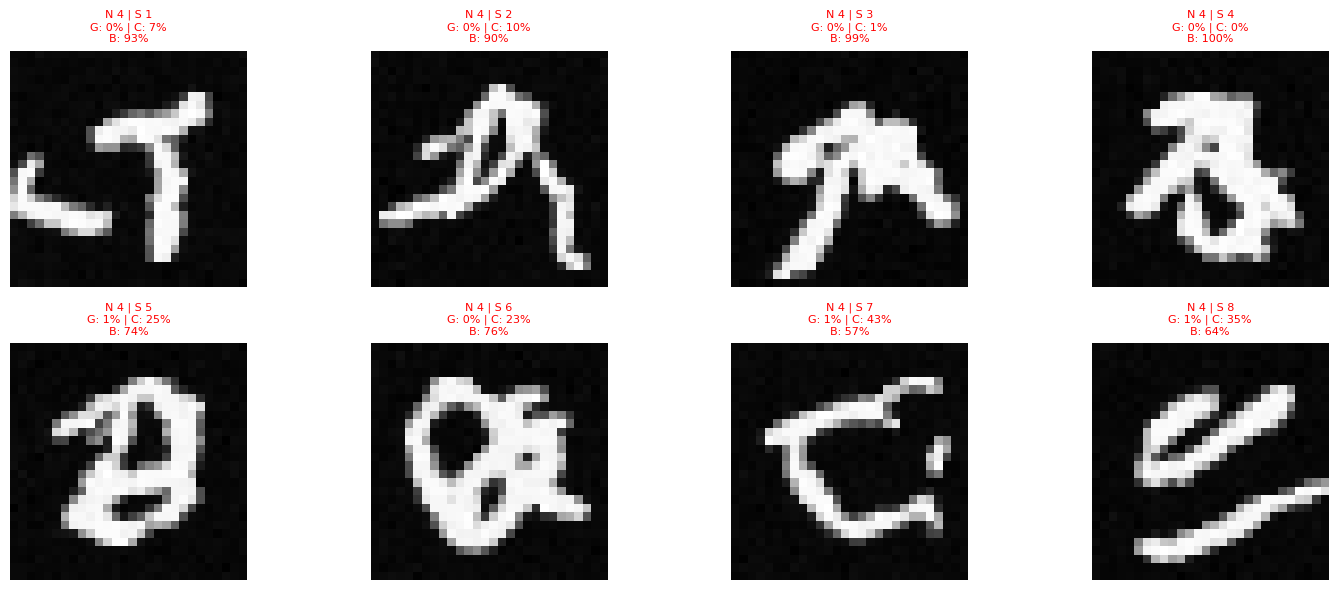


Generating and evaluating number 5...


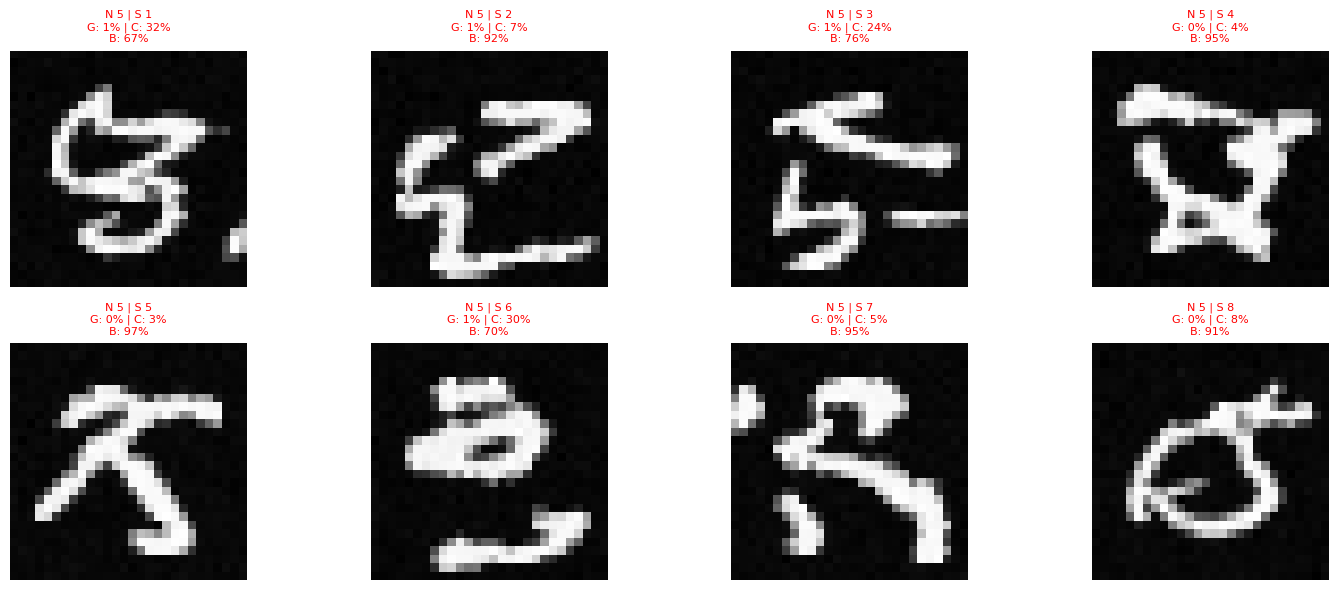


Generating and evaluating number 6...


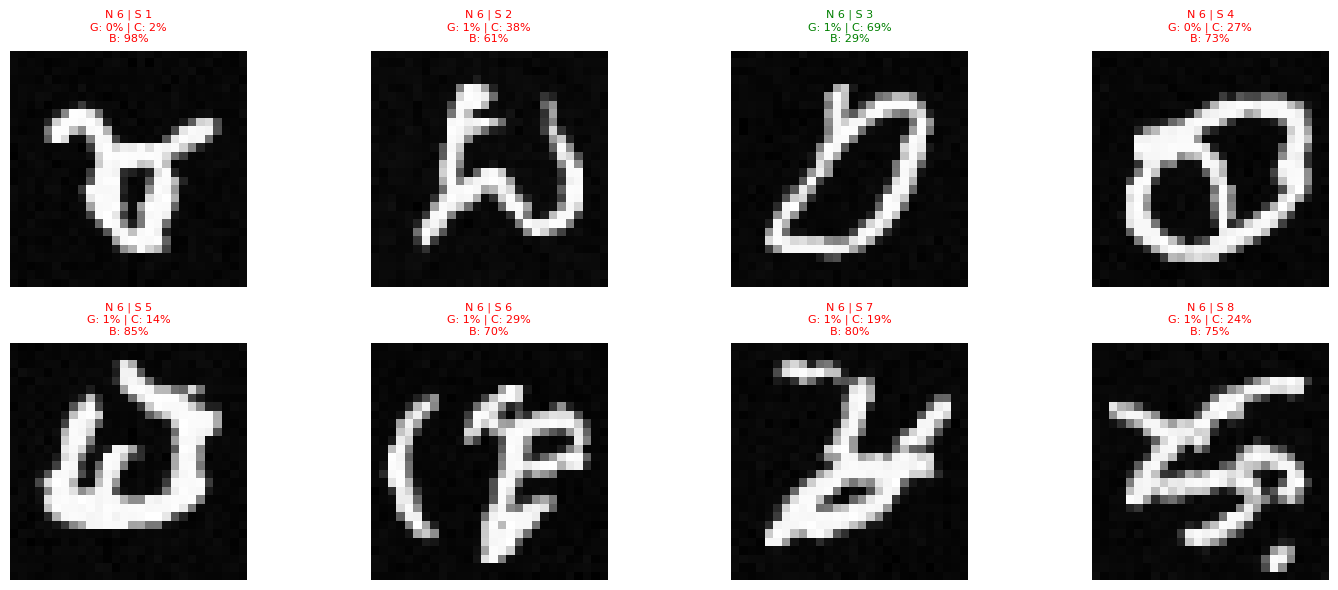


Generating and evaluating number 7...


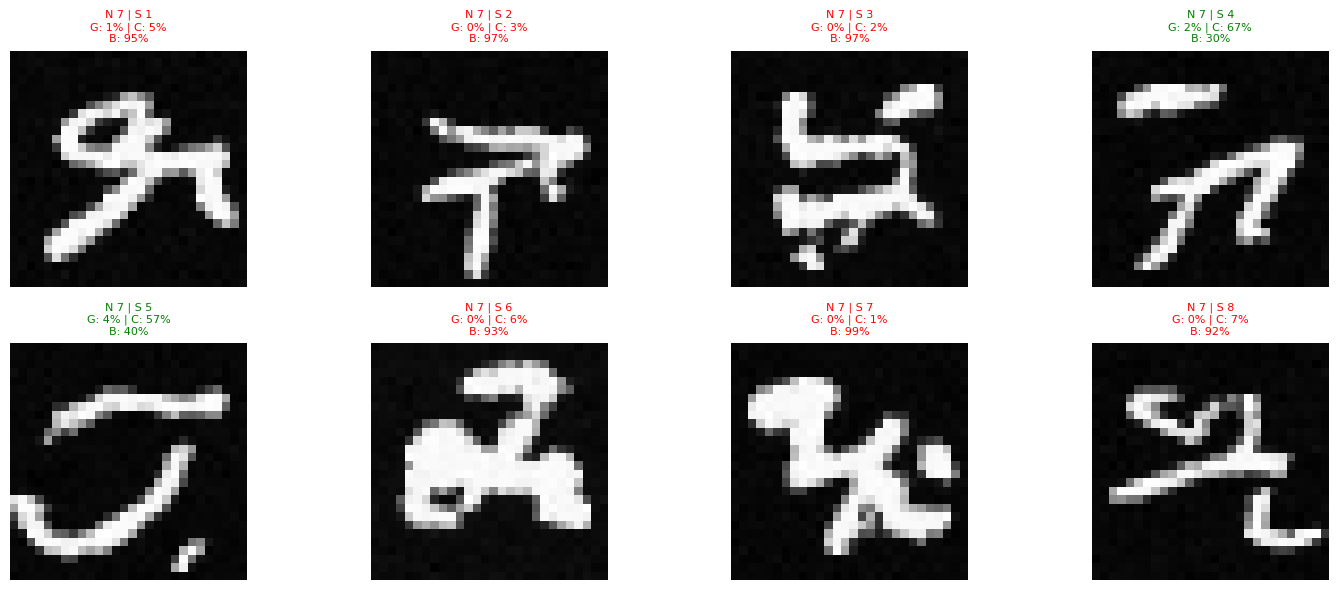


Generating and evaluating number 8...


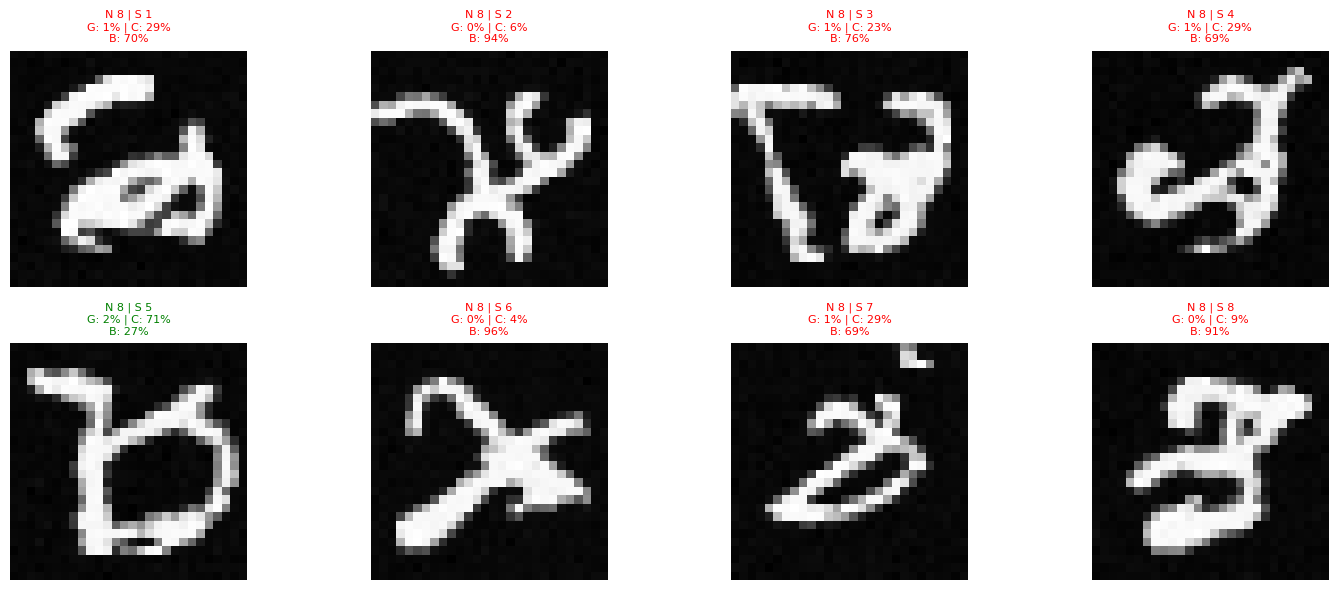


Generating and evaluating number 9...


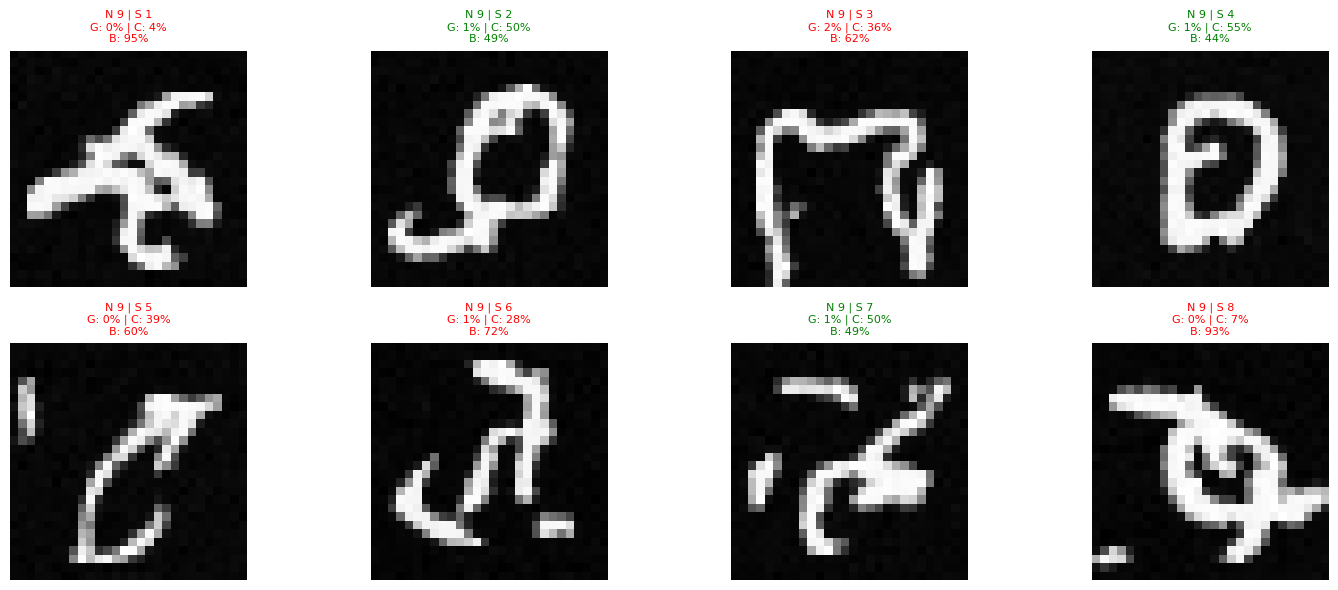

In [66]:
#==============================================================================
# Step 8: CLIP Model Loading and Evaluation Setup
#==============================================================================
try:
    import clip
    clip_available = True
except ImportError:
    clip_available = False

# Safely load CLIP model
try:
    if clip_available:
        clip_model, clip_preprocess = clip.load("ViT-B/32", device=device)
        print(f"✓ Successfully loaded CLIP model: {clip_model.visual.__class__.__name__}")
    else:
        print("CLIP package is not imported. Skipping CLIP initialization.")
except Exception as e:
    print(f"❌ Failed to load CLIP model: {e}")
    clip_available = False

# Define generate_number helper locally to prevent NameError
def local_generate_number(model, number, n_samples=4):
    model.eval()
    with torch.no_grad():
        samples = torch.randn(n_samples, IMG_CH, IMG_SIZE, IMG_SIZE).to(device)
        c = torch.full((n_samples,), number).to(device)
        c_one_hot = F.one_hot(c, N_CLASSES).float().to(device)
        c_mask = torch.ones_like(c.unsqueeze(-1)).to(device)
        for t in range(n_steps-1, -1, -1):
            t_batch = torch.full((n_samples,), t).to(device)
            samples = remove_noise(samples, t_batch, model, c_one_hot, c_mask)
        return samples

def evaluate_with_clip(images, target_number, max_batch_size=16):
    if not clip_available:
        return torch.ones(len(images), 3).to(device) / 3
    try:
        if len(images) > max_batch_size:
            all_similarities = []
            for i in range(0, len(images), max_batch_size):
                batch = images[i:i+max_batch_size]
                with torch.no_grad(), torch.cuda.amp.autocast():
                    batch_similarities = _process_clip_batch(batch, target_number)
                    all_similarities.append(batch_similarities)
                torch.cuda.empty_cache()
            return torch.cat(all_similarities, dim=0)
        else:
            with torch.no_grad(), torch.cuda.amp.autocast():
                return _process_clip_batch(images, target_number)
    except Exception as e:
        print(f"❌ Error in CLIP evaluation: {e}")
        return torch.ones(len(images), 3).to(device) / 3

def _process_clip_batch(images, target_number):
    text_inputs = torch.cat([
        clip.tokenize(f"A handwritten number {target_number}"),
        clip.tokenize(f"A clear, well-written digit {target_number}"),
        clip.tokenize(f"A blurry or unclear number")
    ]).to(device)
    if IMG_CH == 1:
        images_rgb = images.repeat(1, 3, 1, 1)
    else:
        images_rgb = images
    if images_rgb.min() < 0:
        images_rgb = (images_rgb + 1) / 2
    resized_images = F.interpolate(images_rgb, size=(224, 224), mode='bilinear', align_corners=False)
    image_features = clip_model.encode_image(resized_images)
    text_features = clip_model.encode_text(text_inputs)
    image_features = image_features / image_features.norm(dim=-1, keepdim=True)
    text_features = text_features / text_features.norm(dim=-1, keepdim=True)
    similarity = (100.0 * image_features @ text_features.T).softmax(dim=-1)
    return similarity

#==============================================================================
# CLIP Evaluation - Generate and Analyze Sample Digits
#==============================================================================
try:
    for number in range(10):
        print(f"\nGenerating and evaluating number {number}...")
        num_samples_to_eval = 8
        samples = local_generate_number(model, number, n_samples=num_samples_to_eval)

        with torch.no_grad():
            similarities = evaluate_with_clip(samples, number)

        plt.figure(figsize=(15, 6))
        for i in range(num_samples_to_eval):
            plt.subplot(2, 4, i+1)
            if IMG_CH == 1:
                plt.imshow(samples[i][0].cpu(), cmap='gray')
            else:
                img = samples[i].permute(1, 2, 0).cpu()
                if img.min() < 0:
                    img = (img + 1) / 2
                plt.imshow(img)

            good_score = similarities[i][0].item() * 100
            clear_score = similarities[i][1].item() * 100
            blur_score = similarities[i][2].item() * 100

            max_score_idx = torch.argmax(similarities[i]).item()
            title_color = 'green' if max_score_idx < 2 else 'red'

            plt.title(f'N {number} | S {i+1}\nG: {good_score:.0f}% | C: {clear_score:.0f}%\nB: {blur_score:.0f}%', color=title_color, fontsize=8)
            plt.axis('off')

        plt.tight_layout()
        plt.show()
        plt.close()
        torch.cuda.empty_cache()

except Exception as e:
    print(f"❌ Error in generation and evaluation loop: {e}")
    torch.cuda.empty_cache()

In [67]:
# Save the current model state, optimizer state, and loss history safely
import torch
import os

save_path = 'best_diffusion_model.pt'

try:
    # Create a dictionary with all the elements to save
    save_dict = {
        'model_state_dict': model.state_dict(),
    }

    # Add optional elements if they are defined
    if 'optimizer' in locals() or 'optimizer' in globals():
        save_dict['optimizer_state_dict'] = optimizer.state_dict()
    if 'epoch' in locals() or 'epoch' in globals():
        save_dict['epoch'] = epoch
    if 'avg_val_loss' in locals() or 'avg_val_loss' in globals():
        save_dict['best_loss'] = avg_val_loss

    # Create a backup of previous checkpoint if it exists
    if os.path.exists(save_path):
        backup_path = save_path + '.backup'
        try:
            os.replace(save_path, backup_path)
            print(f"Created backup at {backup_path}")
        except Exception as e:
            print(f"Warning: Could not create backup - {e}")

    # Save the new checkpoint
    torch.save(save_dict, save_path)
    print(f"✓ Model successfully saved to {save_path}")

except Exception as e:
    print(f"❌ Error saving model: {e}")
    print("Attempting emergency fallback save...")
    try:
        emergency_path = save_path + '.emergency'
        torch.save(model.state_dict(), emergency_path)
        print(f"✓ Emergency save successful: {emergency_path}")
    except Exception as fallback_err:
        print(f"❌ Emergency save failed: {fallback_err}")


Created backup at best_diffusion_model.pt.backup
✓ Model successfully saved to best_diffusion_model.pt


## Assessment Questions - 10% of ovarall grade

Now that you've completed the exercise, answer these questions include explanations, observations, and your analysis
Support your answers with specific examples from your experiments:

### 1. Understanding Diffusion
- Explain what happens during the forward diffusion process, using your own words and referencing the visualization examples from your notebook.

- Why do we add noise gradually instead of all at once? How does this affect the learning process?

- Look at the step-by-step visualization - at what point (approximately what percentage through the denoising process) can you first recognize the image? Does this vary by image?

### 2. Model Architecture
- Why is the U-Net architecture particularly well-suited for diffusion models? What advantages does it provide over simpler architectures?

- What are skip connections and why are they important? Explain them in relations to our model

- Describe in detail how our model is conditioned to generate specific images. How does the class conditioning mechanism work?

### 3. Training Analysis
- What does the loss value tell of your model tell us?

- How did the quality of  your  generated images change change throughout the training process?

- Why do we need the time embedding in diffusion models? How does it help the model understand where it is in the denoising process?

### 4. CLIP Evaluation
- What do the CLIP scores tell you about your generated images? Which  images got  the highest and lowest quality scores?

- Develop a hypothesis explaining why certain images might be easier or harder for the model to generate convincingly.

- How could CLIP scores be used to improve the diffusion model's generation process? Propose a specific technique.

### 5. Practical Applications
- How could this type of model be useful in the real world?

- What are the limitations of our current model?

- If you were to continue developing this project, what three specific improvements would you make and why?

### Bonus Challenge (Extra 10 points)
Try one or more of these experiments:
1. If you were to continue developing this project, what three specific improvements would you make and why?

2. Modify the U-Net architecture (e.g., add more layers, increase channel dimensions) and train the model. How do these changes affect training time and generation quality?

3. CLIP-Guided Selection: Generate 10 samples of each image, use CLIP to evaluate them, and select the top 3 highest-quality examples of each. Analyze patterns in what CLIP considers "high quality."

4. tyle Conditioning: Modify the conditioning mechanism to generate multiple styles of the same digit (e.g., slanted, thick, thin). Document your approach and results.


Deliverables:
1. A PDF copy of your notebook with
    - Complete code, outputs, and generated images
    - Include all experiment results, training plots, and generated samples
    - CLIP evaluation scores of ythe images you generated
    - Answers and any interesting findings from the bonus challenges